## Cronologia recuperata — sessione IPython 37

Contiene tutte le celle eseguite, inclusi tentativi, ripetizioni ed errori. Non eseguire tutto in blocco.


In [2]:
import dlroms
import numpy as np
import matplotlib.pyplot as plt
import time

## 1. Dati e split train/validation/test

Caricamento del dataset FOM, controllo delle dimensioni e costruzione dei set di addestramento, validazione e test.


In [3]:
# Load FOM dataset
data = np.load("u-bolt.npz")

# Inspect available variables
print(data.files)

mu = data["mu"]
u = data["u"]

print("mu shape:", mu.shape)
print("u shape:", u.shape)

['mu', 'u', 'time']
mu shape: (100, 3)
u shape: (100, 41, 6636)


In [4]:
print("Number of trajectories:", u.shape[0])
print("Number of time snapshots:", u.shape[1])
print("Number of parameters:", mu.shape[1])

print("\nParameter ranges:")
print("mu1:", mu[:, 0].min(), mu[:, 0].max())
print("mu2:", mu[:, 1].min(), mu[:, 1].max())
print("mu3:", mu[:, 2].min(), mu[:, 2].max())

Number of trajectories: 100
Number of time snapshots: 41
Number of parameters: 3

Parameter ranges:
mu1: 0.010374153885699955 0.9890115134756001
mu2: 0.019475241487624584 0.9744830944364566
mu3: 0.00011437481734488664 0.9998672926238792


In [5]:
rng = np.random.default_rng(115)

indices = rng.permutation(len(mu))

train_idx = indices[:60]
val_idx   = indices[60:75]
test_idx  = indices[75:]

mu_train = mu[train_idx]
u_train  = u[train_idx]

mu_val = mu[val_idx]
u_val  = u[val_idx]

mu_test = mu[test_idx]
u_test  = u[test_idx]

print("Training:", mu_train.shape, u_train.shape)
print("Validation:", mu_val.shape, u_val.shape)
print("Test:", mu_test.shape, u_test.shape)

Training: (60, 3) (60, 41, 6636)
Validation: (15, 3) (15, 41, 6636)
Test: (25, 3) (25, 41, 6636)


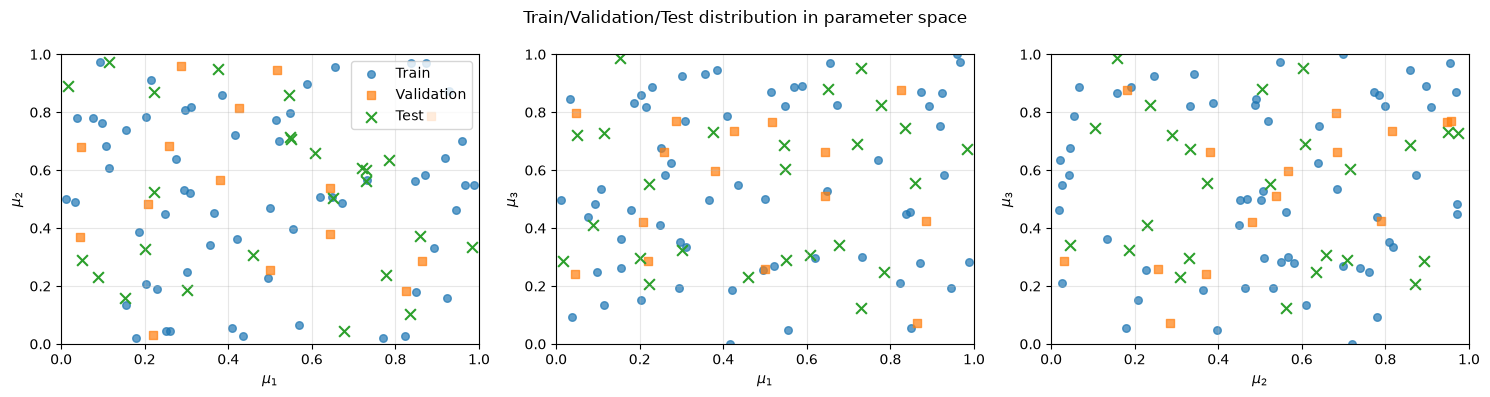

mu_1
  Train:      [0.010, 0.989]
  Validation: [0.046, 0.886]
  Test:       [0.017, 0.984]
mu_2
  Train:      [0.019, 0.972]
  Validation: [0.031, 0.958]
  Test:       [0.045, 0.974]
mu_3
  Train:      [0.000, 1.000]
  Validation: [0.073, 0.877]
  Test:       [0.125, 0.985]

Train mean:       [0.47395169 0.51325018 0.54270732]
Validation mean: [0.44981197 0.53099804 0.53916265]
Test mean:        [0.48776605 0.5062198  0.53576828]

Train std:       [0.29582931 0.28577682 0.28956898]
Validation std: [0.2695021  0.2718249  0.23586758]
Test std:        [0.28501769 0.27424047 0.25159381]


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

pairs = [
    (0, 1, r'$\mu_1$', r'$\mu_2$'),
    (0, 2, r'$\mu_1$', r'$\mu_3$'),
    (1, 2, r'$\mu_2$', r'$\mu_3$')
]

for ax, (i, j, xlabel, ylabel) in zip(axes, pairs):
    ax.scatter(mu_train[:, i], mu_train[:, j],
               label='Train', alpha=0.7, s=30, c='tab:blue')

    ax.scatter(mu_val[:, i], mu_val[:, j],
               label='Validation', alpha=0.7, s=40,
               c='tab:orange', marker='s')

    ax.scatter(mu_test[:, i], mu_test[:, j],
               label='Test', marker='x', s=60, c='tab:green')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)

axes[0].legend(loc='best')

plt.suptitle("Train/Validation/Test distribution in parameter space")
plt.tight_layout()
plt.show()

for i in range(3):
    print(f"mu_{i+1}")
    print(f"  Train:      [{mu_train[:, i].min():.3f}, {mu_train[:, i].max():.3f}]")
    print(f"  Validation: [{mu_val[:, i].min():.3f}, {mu_val[:, i].max():.3f}]")
    print(f"  Test:       [{mu_test[:, i].min():.3f}, {mu_test[:, i].max():.3f}]")

print("\nTrain mean:      ", mu_train.mean(axis=0))
print("Validation mean:", mu_val.mean(axis=0))
print("Test mean:       ", mu_test.mean(axis=0))

print("\nTrain std:      ", mu_train.std(axis=0))
print("Validation std:", mu_val.std(axis=0))
print("Test std:       ", mu_test.std(axis=0))

In [7]:
N_train, N_t, N_h = u_train.shape

snapshots_train = u_train.reshape(N_train * N_t, N_h)  # Ns * N_h number of snapshots x FOM dimension

print("Training trajectories:", N_train)
print("Time steps:", N_t)
print("FOM dimension:", N_h)
print("Snapshot matrix:", snapshots_train.shape)

Training trajectories: 60
Time steps: 41
FOM dimension: 6636
Snapshot matrix: (2460, 6636)


### In final version use integral norm (L^2) to be consistent with the pysichs of the problem (eventualmente riportare comunque discorso sulla differenza nelle 2 norme nella rappresentazione del dominio fisico)

In [8]:
from sklearn.utils.extmath import randomized_svd

# Perform randomized SVD on the snapshot matrix, compute only the first 100 singular values/vectors to speed up the computation
U, s, Vt = randomized_svd(
    snapshots_train,
    n_components=100,
    random_state=42
)

V = Vt.T
# for how we defined the snaposhot matrix, the right singular vectors are the columns of Vt, so we take the transpose to get V

print(U.shape)
print(s.shape)
print(V.shape)

(2460, 100)
(100,)
(6636, 100)


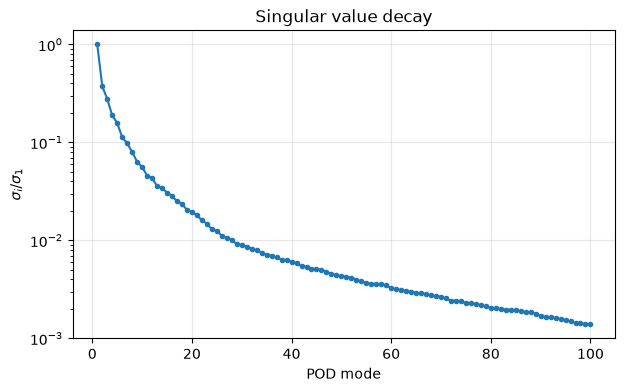

In [9]:
plt.figure(figsize=(7, 4))

plt.semilogy(
    np.arange(1, len(s) + 1),
    s / s[0],
    'o-',
    markersize=3
)

plt.xlabel("POD mode")
plt.ylabel(r"$\sigma_i / \sigma_1$")
plt.title("Singular value decay")
plt.grid(alpha=0.3)

plt.show()

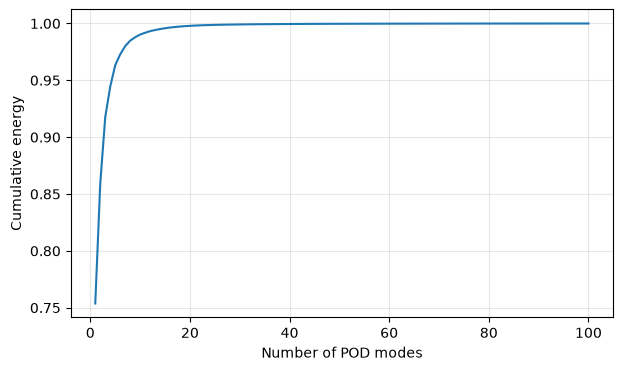

In [ ]:
total_energy = np.linalg.norm(snapshots_train, 'fro')**2  
# We cut the computation at the first 100 SV, but we need the total energy of the snapshot matrix to compute the cumulative energy. 
# The total energy is the sum of the squares of all singular values, which is equal to the squared Frobenius norm of the snapshot matrix.

cumulative_energy = np.cumsum(s**2) / total_energy

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(cumulative_energy) + 1), cumulative_energy)

plt.xlabel("Number of POD modes")
plt.ylabel("Cumulative energy")
plt.grid(alpha=0.3)
plt.show()

In [11]:
thresholds = [0.90, 0.95, 0.99, 0.999]

for threshold in thresholds:
    
    if cumulative_energy[-1] >= threshold:
        n_modes = np.searchsorted(cumulative_energy, threshold) + 1
        print(f"{threshold*100:.1f}% energy -> {n_modes} modes")
    else:
        print(
            f"{threshold*100:.1f}% energy -> "
            f"not reached within first {len(s)} modes"
        )

90.0% energy -> 3 modes
95.0% energy -> 5 modes
99.0% energy -> 10 modes
99.9% energy -> 28 modes


In [12]:
n_modes = 30

V30 = V[:, :n_modes]

snapshots_validation = u_val.reshape(
    u_val.shape[0] * u_val.shape[1],
    u_val.shape[2]
)

print("Validation snapshots:", snapshots_validation.shape)
print("POD basis:", V30.shape)

coeff_validation = snapshots_validation @ V30

snapshots_validation_pod = coeff_validation @ V30.T

print("POD coefficients:", coeff_validation.shape)
print("Reconstructed snapshots:", snapshots_validation_pod.shape)

errors = np.linalg.norm(
    snapshots_validation - snapshots_validation_pod,
    axis=1
) / np.linalg.norm(
    snapshots_validation,
    axis=1
)*100  # relative error in percentage

print(f"Mean relative error: {errors.mean():.4f}%")
print(f"Median relative error: {np.median(errors):.4f}%")
print(f"Max relative error: {errors.max():.4f}%")

Validation snapshots: (615, 6636)
POD basis: (6636, 30)
POD coefficients: (615, 30)
Reconstructed snapshots: (615, 6636)
Mean relative error: 3.5357%
Median relative error: 2.3211%
Max relative error: 38.5168%


Mean validation error: 3.5357
Worst trajectory: 4.8414
Worst validation trajectory: 13
Mean error: 4.84%
Parameters: [0.04604099 0.37024232 0.24231827]


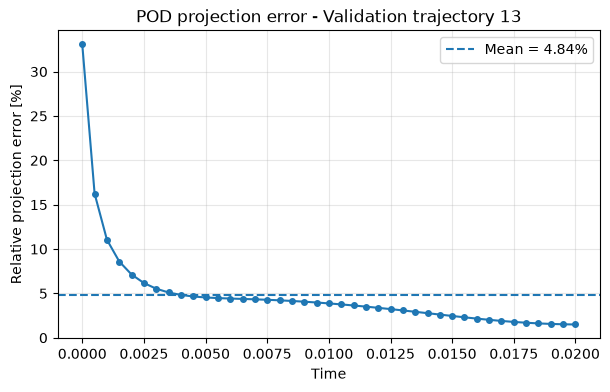

In [13]:
errors_trajectory = errors.reshape(
    u_val.shape[0],
    u_val.shape[1]
)

mean_error_per_trajectory = errors_trajectory.mean(axis=1)

print(
    f"Mean validation error: "
    f"{mean_error_per_trajectory.mean():.4f}"
)

print(
    f"Worst trajectory: "
    f"{mean_error_per_trajectory.max():.4f}"
)

worst_idx = np.argmax(mean_error_per_trajectory)

print("Worst validation trajectory:", worst_idx)
print(f"Mean error: {mean_error_per_trajectory[worst_idx]:.2f}%")
print("Parameters:", mu_val[worst_idx])
time_grid = np.linspace(0, 0.02, u_val.shape[1])
plt.figure(figsize=(7, 4))

plt.plot(
    time_grid,
    errors_trajectory[worst_idx],
    'o-',
    markersize=4
)

plt.axhline(
    mean_error_per_trajectory[worst_idx],
    linestyle='--',
    label=f'Mean = {mean_error_per_trajectory[worst_idx]:.2f}%'
)

plt.xlabel("Time")
plt.ylabel("Relative projection error [%]")
plt.title(f"POD projection error - Validation trajectory {worst_idx}")

plt.grid(alpha=0.3)
plt.legend()
plt.show()

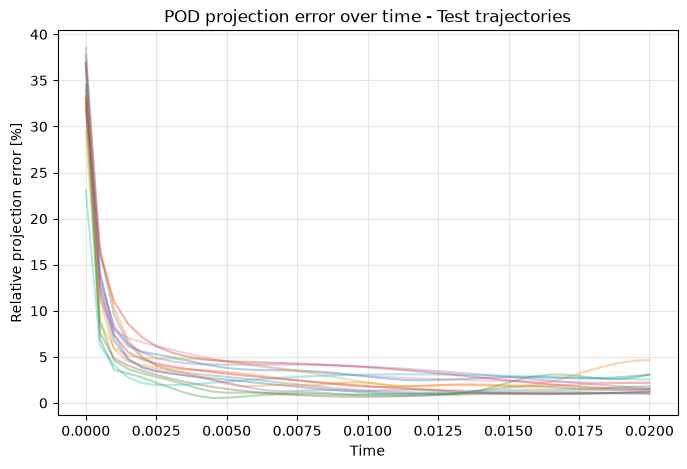

In [14]:
plt.figure(figsize=(8, 5))

for i in range(errors_trajectory.shape[0]):
    plt.plot(
        time_grid,
        errors_trajectory[i],
        alpha=0.35
    )

plt.xlabel("Time")
plt.ylabel("Relative projection error [%]")
plt.title("POD projection error over time - Test trajectories")

plt.grid(alpha=0.3)
plt.show()

 3 modes -> 36.45%
 5 modes -> 25.54%
10 modes -> 12.02%
20 modes -> 5.24%
30 modes -> 3.54%
50 modes -> 2.14%
75 modes -> 1.53%
100 modes -> 1.21%


<Figure size 700x400 with 0 Axes>

<Figure size 700x400 with 0 Axes>

<Figure size 700x400 with 0 Axes>

<Figure size 700x400 with 0 Axes>

<Figure size 700x400 with 0 Axes>

<Figure size 700x400 with 0 Axes>

<Figure size 700x400 with 0 Axes>

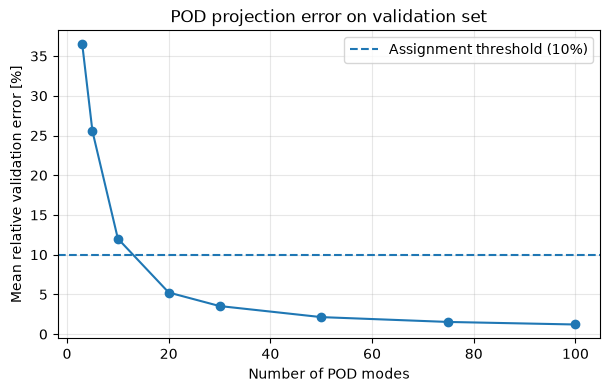

In [15]:
modes_to_test = [3, 5, 10, 20, 30, 50, 75, 100]
pod_errors = []

for n in modes_to_test:
    
    Vn = V[:, :n]

    # Projection onto POD space
    coeff = snapshots_validation @ Vn
    reconstruction = coeff @ Vn.T

    # Relative error for each snapshot [%]
    errors = (
        np.linalg.norm(snapshots_validation - reconstruction, axis=1)
        / np.linalg.norm(snapshots_validation, axis=1)
    ) * 100

    # Restore trajectory/time structure
    errors = errors.reshape(
        u_val.shape[0],
        u_val.shape[1]
    )

    pod_errors.append(errors.mean())

# Print results
for n, error in zip(modes_to_test, pod_errors):
    print(f"{n:2d} modes -> {error:.2f}%")

    plt.figure(figsize=(7, 4))

plt.plot(
    modes_to_test,
    pod_errors,
    'o-'
)
plt.axhline(
    y=10,
    linestyle='--',
    label='Assignment threshold (10%)'
)

plt.xlabel("Number of POD modes")
plt.ylabel("Mean relative validation error [%]")
plt.title("POD projection error on validation set")

plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [16]:
T = 0.02
t = np.linspace(0, T, N_t)

In [17]:
mu_train_repeated = np.repeat(mu_train, N_t, axis=0)

t_train = np.tile(t, len(mu_train)).reshape(-1, 1)

X_train_nn = np.hstack([
    mu_train_repeated,
    t_train
])

print(X_train_nn.shape)

(2460, 4)


In [18]:
n_modes = 30
V30= V[:, :n_modes]

snapshots_train = u_train.reshape(-1, u_train.shape[-1])

A_train = snapshots_train @ V30

print(A_train.shape)

(2460, 30)


In [19]:
mu_val_repeated = np.repeat(mu_val, N_t, axis=0)
t_val = np.tile(t, len(mu_val)).reshape(-1, 1)

X_val_nn = np.hstack([
    mu_val_repeated,
    t_val
])

snapshots_val = u_val.reshape(-1, u_val.shape[-1])

A_val = snapshots_val @ V30

print("X train:", X_train_nn.shape)
print("A train:", A_train.shape)

print("X val:", X_val_nn.shape)
print("A val:", A_val.shape)

X train: (2460, 4)
A train: (2460, 30)
X val: (615, 4)
A val: (615, 30)


## 2. Riduzione POD e preparazione delle traiettorie

Qui si costruisce la base POD tramite SVD, si esaminano le energie e si prepara la matrice dei coefficienti da usare nel regressore.


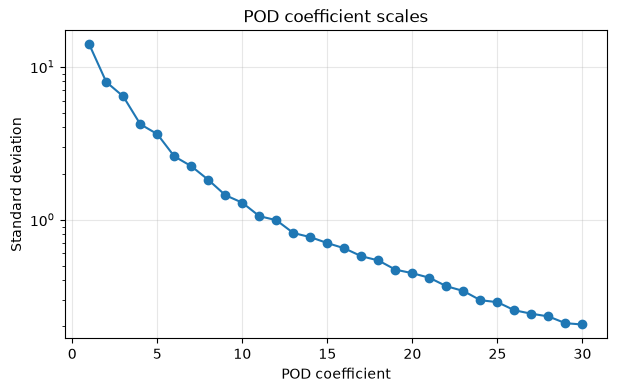

In [21]:
# Check the standard deviation of the POD coefficients to see if normalization is needed
a_std = A_train.std(axis=0)

plt.figure(figsize=(7,4))
plt.semilogy(np.arange(1, n_modes + 1), a_std, 'o-')
plt.xlabel("POD coefficient")
plt.ylabel("Standard deviation")
plt.title("POD coefficient scales")
plt.grid(alpha=0.3)
plt.show()

In [22]:
# Normalize POD coefficients to [0, 1] for neural network training
a_min = A_train.min(axis=0) # Get minimum values of each POD coefficient across all training snapshots
a_max = A_train.max(axis=0) # Get maximum values of each POD coefficient across all training snapshots
a_range = a_max - a_min # Compute the range (max - min) for each POD coefficient
A_train_scaled = (A_train - a_min) / a_range # Scaling A_train to [0, 1] range for each POD coefficient
A_val_scaled = (A_val - a_min) / a_range # Scaling A_val using the same min and max values from A_train to ensure consistency in scaling between training and validation data

## 3. Regressore neurale sui coefficienti POD

Normalizzazione dei coefficienti, definizione del modello PyTorch e addestramento del regressore per predire i coefficienti POD in funzione di parametri e tempo.


In [23]:
import torch
import torch.nn as nn
# Using torch package instead of Dense

N = 30

model = nn.Sequential(
    nn.Linear(4, 64),
    nn.LeakyReLU(0.1),

    nn.Linear(64, 64),
    nn.LeakyReLU(0.1),

    nn.Linear(64, 64),
    nn.LeakyReLU(0.1),

    nn.Linear(64, N)
)

In [24]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
# Using torch package instead of Dense

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cpu


In [25]:
X_train_tensor = torch.tensor(X_train_nn, dtype=torch.float32)
A_train_tensor = torch.tensor(A_train, dtype=torch.float32)
A_train_scaled_tensor = torch.tensor(A_train_scaled, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_nn, dtype=torch.float32)
A_val_tensor = torch.tensor(A_val, dtype=torch.float32)
A_val_scaled_tensor = torch.tensor(A_val_scaled, dtype=torch.float32)

a_min_tensor = torch.tensor(a_min, dtype=torch.float32).to(device)
a_range_tensor = torch.tensor(a_range, dtype=torch.float32).to(device)

print(X_train_tensor.shape)
print(A_train_scaled_tensor.shape)

print(X_val_tensor.shape)
print(A_val_scaled_tensor.shape)

torch.Size([2460, 4])
torch.Size([2460, 30])
torch.Size([615, 4])
torch.Size([615, 30])


In [26]:
# Normalize POD coefficients to [0, 1] for neural network training
a_min = A_train.min(axis=0) # Get minimum values of each POD coefficient across all training snapshots
a_max = A_train.max(axis=0) # Get maximum values of each POD coefficient across all training snapshots
a_range = a_max - a_min # Calculate the range (max - min) for each POD coefficient

A_train_scaled = (A_train - a_min) / a_range # Scaling A_train to [0, 1] range for each POD coefficient
A_val_scaled = (A_val - a_min) / a_range # Scaling A_val using the same min and max values from A_train to ensure consistency in scaling between training and validation data

In [27]:
X_train_tensor = torch.tensor(X_train_nn, dtype=torch.float32)
A_train_tensor = torch.tensor(A_train, dtype=torch.float32)
A_train_scaled_tensor = torch.tensor(A_train_scaled, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_nn, dtype=torch.float32)
A_val_tensor = torch.tensor(A_val, dtype=torch.float32)
A_val_scaled_tensor = torch.tensor(A_val_scaled, dtype=torch.float32)

a_min_tensor = torch.tensor(a_min, dtype=torch.float32).to(device)
a_range_tensor = torch.tensor(a_range, dtype=torch.float32).to(device)

print(X_train_tensor.shape)
print(A_train_scaled_tensor.shape)

print(X_val_tensor.shape)
print(A_val_scaled_tensor.shape)

torch.Size([2460, 4])
torch.Size([2460, 30])
torch.Size([615, 4])
torch.Size([615, 30])


In [28]:
train_dataset = TensorDataset(
    X_train_tensor,
    A_train_scaled_tensor,
    A_train_tensor
)

In [29]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

In [ ]:
n_modes = 30

model = nn.Sequential(
    nn.Linear(4, 64),
    nn.LeakyReLU(0.1),

    nn.Linear(64, 64),
    nn.LeakyReLU(0.1),

    nn.Linear(64, 64),
    nn.LeakyReLU(0.1),

    nn.Linear(64, n_modes)
).to(device)

print(model)

Sequential(
  (0): Linear(in_features=4, out_features=64, bias=True)
  (1): LeakyReLU(negative_slope=0.1)
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): LeakyReLU(negative_slope=0.1)
  (4): Linear(in_features=64, out_features=64, bias=True)
  (5): LeakyReLU(negative_slope=0.1)
  (6): Linear(in_features=64, out_features=30, bias=True)
)


In [31]:
n_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", n_parameters)

Trainable parameters: 10590


In [32]:
criterion = nn.MSELoss()

def coefficient_loss(pred_scaled, target):
    pred = pred_scaled * a_range_tensor + a_min_tensor
    return criterion(pred, target)

In [33]:
print("CUDA available:", torch.cuda.is_available())
print("PyTorch version:", torch.__version__)
print("CUDA version used by PyTorch:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: False
PyTorch version: 2.4.1+cpu
CUDA version used by PyTorch: None


In [34]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

In [35]:
X_batch, A_scaled_batch, A_batch = next(iter(train_loader))

In [36]:
X_batch, A_scaled_batch, A_batch = next(iter(train_loader))

In [37]:
print(X_batch.shape)
print(A_scaled_batch.shape)
print(A_batch.shape)

torch.Size([64, 4])
torch.Size([64, 30])
torch.Size([64, 30])


In [38]:
X_batch = X_batch.to(device)
A_batch = A_batch.to(device)

In [39]:
pred_scaled = model(X_batch)

In [40]:
print(pred_scaled.shape)

torch.Size([64, 30])


In [41]:
loss = coefficient_loss(pred_scaled, A_batch)

print(loss.item())

44.72859573364258


In [42]:
model.train()

train_loss = 0.0

for X_batch, _, A_batch in train_loader:

    X_batch = X_batch.to(device)
    A_batch = A_batch.to(device)

    optimizer.zero_grad()

    pred_scaled = model(X_batch)

    loss = coefficient_loss(pred_scaled, A_batch)

    loss.backward()

    optimizer.step()

    train_loss += loss.item() * X_batch.size(0)

train_loss /= len(train_dataset)

print("Training loss:", train_loss)

Training loss: 22.616819239050393


In [43]:
X_val_device = X_val_tensor.to(device)
A_val_device = A_val_tensor.to(device)

In [44]:
X_val_device = X_val_tensor.to(device)
A_val_device = A_val_tensor.to(device)

In [45]:
X_val_device = X_val_tensor.to(device)
A_val_device = A_val_tensor.to(device)

In [46]:
X_val_device = X_val_tensor.to(device)
A_val_device = A_val_tensor.to(device)

In [47]:
X_val_device = X_val_tensor.to(device)
A_val_device = A_val_tensor.to(device)
model.eval()

with torch.no_grad():

    pred_val_scaled = model(X_val_device)

    val_loss = coefficient_loss(
        pred_val_scaled,
        A_val_device
    )

In [48]:
n_epochs = 500

train_losses = []
val_losses = []

for epoch in range(n_epochs):

    # ----- TRAINING -----

    model.train()

    train_loss = 0.0

    for X_batch, _, A_batch in train_loader:

        X_batch = X_batch.to(device)
        A_batch = A_batch.to(device)

        optimizer.zero_grad()

        pred_scaled = model(X_batch)

        loss = coefficient_loss(
            pred_scaled,
            A_batch
        )

        loss.backward()

        optimizer.step()

        train_loss += loss.item() * X_batch.size(0)

    train_loss /= len(train_dataset)


    # ----- VALIDATION -----

    model.eval()

    with torch.no_grad():

        pred_val_scaled = model(X_val_device)

        val_loss = coefficient_loss(
            pred_val_scaled,
            A_val_device
        ).item()


    # ----- SAVE HISTORY -----

    train_losses.append(train_loss)
    val_losses.append(val_loss)


    # ----- PRINT -----

    if (epoch + 1) % 50 == 0:

        print(
            f"Epoch {epoch+1:4d} | "
            f"Train loss: {train_loss:.6f} | "
            f"Val loss: {val_loss:.6f}"
        )

Epoch   50 | Train loss: 0.325274 | Val loss: 0.399772
Epoch  100 | Train loss: 0.166893 | Val loss: 0.222376
Epoch  150 | Train loss: 0.117604 | Val loss: 0.175119
Epoch  200 | Train loss: 0.088966 | Val loss: 0.141854
Epoch  250 | Train loss: 0.071122 | Val loss: 0.125613
Epoch  300 | Train loss: 0.058790 | Val loss: 0.119498
Epoch  350 | Train loss: 0.050977 | Val loss: 0.114058
Epoch  400 | Train loss: 0.044730 | Val loss: 0.104156
Epoch  450 | Train loss: 0.038362 | Val loss: 0.110148
Epoch  500 | Train loss: 0.037597 | Val loss: 0.098414


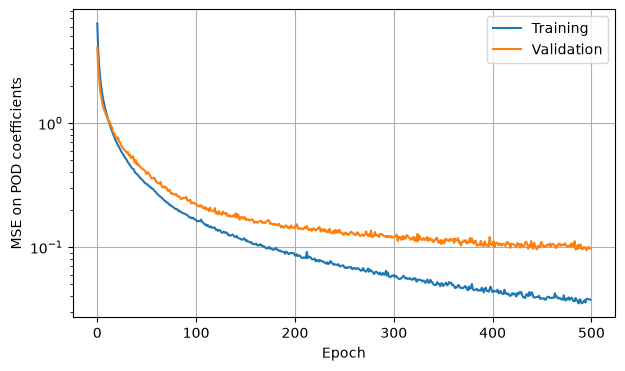

In [49]:
plt.figure(figsize=(7, 4))

plt.semilogy(train_losses, label="Training")
plt.semilogy(val_losses, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("MSE on POD coefficients")
plt.legend()
plt.grid()

plt.show()

In [50]:
model.eval()

with torch.no_grad():
    pred_val_scaled = model(X_val_device)

    # ritorniamo alla scala originale dei coefficienti POD
    A_val_pred = (
        pred_val_scaled * a_range_tensor + a_min_tensor
    )

# Torniamo a NumPy
A_val_pred = A_val_pred.cpu().numpy()

# Ricostruzione del campo
snapshots_val_pred = A_val_pred @ V30.T

print("Predicted coefficients:", A_val_pred.shape)
print("Reconstructed snapshots:", snapshots_val_pred.shape)

Predicted coefficients: (615, 30)
Reconstructed snapshots: (615, 6636)


In [51]:
errors_nn = (
    np.linalg.norm(
        snapshots_val - snapshots_val_pred,
        axis=1
    )
    /
    np.linalg.norm(
        snapshots_val,
        axis=1
    )
)

print(f"Mean POD-NN validation error: {100*np.mean(errors_nn):.2f}%")
print(f"Median POD-NN validation error: {100*np.median(errors_nn):.2f}%")
print(f"Max POD-NN validation error: {100*np.max(errors_nn):.2f}%")

Mean POD-NN validation error: 8.85%
Median POD-NN validation error: 6.28%
Max POD-NN validation error: 66.67%


In [52]:
errors_nn = errors_nn.reshape(len(mu_val), N_t)

trajectory_errors_nn = errors_nn.mean(axis=1)

print(
    f"Mean over trajectories: "
    f"{100*np.mean(trajectory_errors_nn):.2f}%"
)

print(
    f"Worst trajectory: "
    f"{100*np.max(trajectory_errors_nn):.2f}%"
)

Mean over trajectories: 8.85%
Worst trajectory: 14.58%


In [53]:
errors_nn = errors_nn.reshape(len(mu_val), N_t)

trajectory_errors_nn = errors_nn.mean(axis=1)

print(
    f"Mean over trajectories: "
    f"{100*np.mean(trajectory_errors_nn):.2f}%"
)

print(
    f"Worst trajectory: "
    f"{100*np.max(trajectory_errors_nn):.2f}%"
)

Mean over trajectories: 8.85%
Worst trajectory: 14.58%


In [54]:
print(trajectory_errors_nn * 100)

[11.40947615  7.95038224  8.06158001  9.09319634 14.58184531  5.26092409
 11.15113701  6.8375997   6.56520861  7.12164681  7.12842411  9.09363725
  8.00721989 11.86893745  8.5761062 ]


In [55]:
errors_nn = errors_nn.reshape(len(mu_val), N_t)

trajectory_errors_nn = errors_nn.mean(axis=1)

print(
    f"Mean over trajectories: "
    f"{100*np.mean(trajectory_errors_nn):.2f}%"
)

print(
    f"Worst trajectory: "
    f"{100*np.max(trajectory_errors_nn):.2f}%"
)

Mean over trajectories: 8.85%
Worst trajectory: 14.58%


In [56]:
errors_nn = errors_nn.reshape(len(mu_val), N_t)

trajectory_errors_nn = errors_nn.mean(axis=1)

print(
    f"Mean over trajectories: "
    f"{100*np.mean(trajectory_errors_nn):.2f}%"
)

print(
    f"Worst trajectory: "
    f"{100*np.max(trajectory_errors_nn):.2f}%"
)
print(trajectory_errors_nn * 100)

Mean over trajectories: 8.85%
Worst trajectory: 14.58%
[11.40947615  7.95038224  8.06158001  9.09319634 14.58184531  5.26092409
 11.15113701  6.8375997   6.56520861  7.12164681  7.12842411  9.09363725
  8.00721989 11.86893745  8.5761062 ]


## 4. Validazione finale e errore L2 FEM

In questa sezione si valutano le previsioni del modello e si confrontano le traiettorie ricostruite con la soluzione di riferimento tramite errore relativo in norma L2.


In [65]:
import dlroms.fespaces as fe
points = [np.array([0.0, 0.0])]

def step(z):
    points.append(points[-1] + [z.real, z.imag])

def arch(r, thetas, knots=30):
    rho = np.abs(r)
    center = points[-1] + [r.real, r.imag]
    th = np.linspace(*thetas, knots)[1:]
    shift = rho * np.exp(1j * th)

    vals = np.stack([
        center[0] + shift.real,
        center[1] + shift.imag
    ], axis=1)

    for v in vals:
        points.append(v)

step(3j)
arch(2, thetas=(np.pi, 0))
step(-3j)
step(-1)
step(3j)
arch(-1, thetas=(0, np.pi))
step(-3j)
step(-1)

points = np.stack(points)

domain = fe.polygon(points)
mesh = fe.mesh(domain, stepsize=0.05)
Vh = fe.space(mesh, 'CG', 1)

print("FEM DOFs:", fe.dofs(Vh).shape)
print("Dataset DOFs:", u.shape[-1])

FEM DOFs: (6636, 2)
Dataset DOFs: 6636


In [ ]:
u_trial = fe.dolfin.TrialFunction(Vh)
v_test  = fe.dolfin.TestFunction(Vh)

M = fe.assemble(
    lambda u, v: fe.inner(u, v) * fe.dx,
    Vh
)

print(type(M))
print(M.shape)


Calling FFC just-in-time (JIT) compiler, this may take some time.
<class 'scipy.sparse._csr.csr_matrix'>
(6636, 6636)
<class 'scipy.sparse._csr.csr_matrix'>
(6636, 6636)


In [71]:
error_val = snapshots_val - snapshots_val_pred

# ||e||_L2² = e^T M e
error_L2_sq = np.sum(
    (error_val @ M) * error_val,
    axis=1
)

# ||u||_L2² = u^T M u
true_L2_sq = np.sum(
    (snapshots_val @ M) * snapshots_val,
    axis=1
)

errors_nn_L2 = np.sqrt(
    error_L2_sq / true_L2_sq
)

(error_val @ M) * error_val

errors_nn_L2 = errors_nn_L2.reshape(len(mu_val), N_t)

trajectory_errors_L2 = errors_nn_L2.mean(axis=1)

print(
    f"Mean L2 validation error: "
    f"{100 * trajectory_errors_L2.mean():.2f}%"
)

print(
    f"Worst trajectory L2 error: "
    f"{100 * trajectory_errors_L2.max():.2f}%"
)

print(100 * trajectory_errors_L2)

Mean L2 validation error: 8.72%
Worst trajectory L2 error: 14.26%
[11.22209689  7.76505469  8.20279297  9.10862616 14.25888115  5.11303096
 10.84006192  6.58207913  6.36724767  7.0203607   6.98439226  9.12025167
  8.18721192 11.51213807  8.56409376]


In [72]:
# Ricostruzione ideale mediante POD:
# qui usiamo i coefficienti POD veri, non quelli predetti dalla NN
snapshots_val_pod = A_val @ V30.T

pod_error = snapshots_val - snapshots_val_pod

pod_error_L2_sq = np.sum(
    (pod_error @ M) * pod_error,
    axis=1
)

true_L2_sq = np.sum(
    (snapshots_val @ M) * snapshots_val,
    axis=1
)

errors_pod_L2 = np.sqrt(
    pod_error_L2_sq / true_L2_sq
)

errors_pod_L2 = errors_pod_L2.reshape(len(mu_val), N_t)

trajectory_errors_pod_L2 = errors_pod_L2.mean(axis=1)

print(
    f"POD projection L2 error: "
    f"{100 * trajectory_errors_pod_L2.mean():.2f}%"
)

POD projection L2 error: 3.20%


In [73]:
import copy

# Continuiamo dal modello già allenato per 500 epochs
additional_epochs = 1000

# Scheduler: se la validation non migliora per 100 epochs,
# dimezza il learning rate
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=100
)

# Il modello attuale è il nostro punto di partenza
best_val_loss = val_losses[-1]
best_state = copy.deepcopy(model.state_dict())

tuning_train_losses = []
tuning_val_losses = []

for epoch in range(additional_epochs):

    # ----- TRAINING -----
    model.train()
    train_loss = 0.0

    for X_batch, _, A_batch in train_loader:

        X_batch = X_batch.to(device)
        A_batch = A_batch.to(device)

        optimizer.zero_grad()

        pred_scaled = model(X_batch)

        loss = coefficient_loss(
            pred_scaled,
            A_batch
        )

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * X_batch.size(0)

    train_loss /= len(train_dataset)

    # ----- VALIDATION -----
    model.eval()

    with torch.no_grad():

        pred_val_scaled = model(X_val_device)

        val_loss = coefficient_loss(
            pred_val_scaled,
            A_val_device
        ).item()

    # ----- LR SCHEDULER -----
    scheduler.step(val_loss)

    # ----- SAVE BEST MODEL -----
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_state = copy.deepcopy(
            model.state_dict()
        )

    # ----- SAVE HISTORY -----
    tuning_train_losses.append(train_loss)
    tuning_val_losses.append(val_loss)

    # ----- PRINT -----
    if (epoch + 1) % 100 == 0:

        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Epoch {500 + epoch + 1:4d} | "
            f"Train: {train_loss:.6f} | "
            f"Val: {val_loss:.6f} | "
            f"LR: {current_lr:.2e}"
        )


# Ripristiniamo automaticamente il modello migliore
model.load_state_dict(best_state)

print("\nBest validation loss:", best_val_loss)

Epoch  600 | Train: 0.030229 | Val: 0.092992 | LR: 1.00e-03
Epoch  700 | Train: 0.026575 | Val: 0.093104 | LR: 1.00e-03
Epoch  800 | Train: 0.024571 | Val: 0.087995 | LR: 1.00e-03
Epoch  900 | Train: 0.022092 | Val: 0.092987 | LR: 1.00e-03
Epoch 1000 | Train: 0.018025 | Val: 0.089008 | LR: 5.00e-04
Epoch 1100 | Train: 0.015523 | Val: 0.087099 | LR: 2.50e-04
Epoch 1200 | Train: 0.014598 | Val: 0.087555 | LR: 1.25e-04
Epoch 1300 | Train: 0.014086 | Val: 0.087211 | LR: 6.25e-05
Epoch 1400 | Train: 0.013776 | Val: 0.086942 | LR: 3.13e-05
Epoch 1500 | Train: 0.013588 | Val: 0.087248 | LR: 1.56e-05

Best validation loss: 0.08477160334587097


In [75]:
model.eval()

with torch.no_grad():
    pred_val_scaled = model(X_val_device)

    A_val_pred = (
        pred_val_scaled * a_range_tensor
        + a_min_tensor
    )

A_val_pred = A_val_pred.cpu().numpy()

# Ricostruzione del campo
snapshots_val_pred = A_val_pred @ V30.T

error_val = snapshots_val - snapshots_val_pred

error_L2_sq = np.sum(
    (error_val @ M) * error_val,
    axis=1
)

true_L2_sq = np.sum(
    (snapshots_val @ M) * snapshots_val,
    axis=1
)

errors_nn_L2 = np.sqrt(
    error_L2_sq / true_L2_sq
)

errors_nn_L2 = errors_nn_L2.reshape(
    len(mu_val), N_t
)

trajectory_errors_L2 = errors_nn_L2.mean(axis=1)

print(
    f"Mean L2 validation error: "
    f"{100 * trajectory_errors_L2.mean():.2f}%"
)

print(
    f"Worst trajectory L2 error: "
    f"{100 * trajectory_errors_L2.max():.2f}%"
)

print(100 * trajectory_errors_L2)

Mean L2 validation error: 8.12%
Worst trajectory L2 error: 14.66%
[10.10347432  6.7769099   7.98009847  8.28106941 13.22993566  4.2963782
  8.76906186  5.82449305  5.79113165  6.12645612  6.35050701  8.86142969
  7.33315008 14.66019126  7.41313076]


## Tuning

## Hyperparameter selection strategy

The performance of the POD-NN depends on several interacting design choices, including the network architecture (depth and width), regularization, learning rate, activation function, and POD dimension.

These hyperparameters cannot in general be optimized independently: changing one of them may alter which value of another hyperparameter is optimal. For instance, a larger network may initially generalize worse than a smaller one but benefit more strongly from regularization, while different architectures may require different learning rates to reach their best solutions.

A complete Cartesian search over all possible combinations would therefore be the most exhaustive approach. However, even for a relatively small set of candidate values, this would rapidly become computationally expensive and would also increase the risk of progressively adapting the design to the validation set.

For this reason, a **sequential, theory-guided hyperparameter selection strategy** is adopted instead.

### Error sources and interpretation of the hyperparameters

For a POD-NN approximation, the overall approximation error can be conceptually separated into different contributions:

$$
E_{\mathrm{ROM}}
\sim
E_{\mathrm{sampling}}
+
E_{\mathrm{POD}}
+
E_{\mathrm{NN}},
$$

where:

- $E_{\mathrm{sampling}}$ is associated with the finite sampling of the parameter space;
- $E_{\mathrm{POD}}$ is associated with the projection onto a finite-dimensional POD space;
- $E_{\mathrm{NN}}$ is associated with the neural-network approximation of the reduced coordinates.

The neural-network contribution can itself be interpreted qualitatively as resulting from different effects:

$$
E_{\mathrm{NN}}
\sim
E_{\mathrm{approx}}
+
E_{\mathrm{optimization}}
+
E_{\mathrm{generalization}}.
$$

This is not intended as an exact additive error decomposition, but rather as a useful conceptual framework for interpreting the role of the different hyperparameters.

**Network depth and width** primarily determine the expressive capacity of the model and therefore its ability to approximate the reduced map

$$
(\boldsymbol{\mu},t)
\longmapsto
\mathbf{a}(\boldsymbol{\mu},t).
$$

Insufficient capacity leads to underfitting and therefore to a large approximation error.

The **learning rate** mainly affects the optimization process. A sufficiently expressive network may still perform poorly if the optimization algorithm does not reach a suitable region of the parameter space.

**Weight decay** introduces an $L^2$ penalty on the network parameters:

$$
\mathcal{L}_{\mathrm{reg}}
=
\mathcal{L}_{\mathrm{data}}
+
\lambda \|\boldsymbol{\theta}\|_2^2,
$$

where $\lambda$ is the regularization coefficient. It controls the trade-off between fitting the training data and obtaining a solution that generalizes to unseen parameter trajectories.

The **activation function** affects both the class of functions represented by the network and the optimization process. In the present problem, smooth activation functions may be of particular interest because the network approximates a parameter-to-reduced-solution map generated by a parametrized PDE.

Consequently, there is no general analytical rule providing an optimal combination of architecture, learning rate, regularization and activation function. Approximation-theory results, such as the neural-network complexity estimates discussed in the course, can provide guidance on the required expressive capacity, but they do not determine the optimal training hyperparameters.

---

### Sequential rather than exhaustive hyperparameter search

The hyperparameters are therefore investigated sequentially. At each stage, clearly inadequate configurations are discarded and only a small number of promising candidates are retained for the subsequent stage.

The adopted procedure is

$$
\text{Architecture}
\rightarrow
\text{Regularization}
\rightarrow
\text{Learning rate}
\rightarrow
\text{Activation function}
\rightarrow
\text{Robustness to initialization}.
$$

This procedure represents a **greedy/sequential hyperparameter search** and is not guaranteed to recover the globally optimal combination.

For example, an architecture that is suboptimal using the initial learning rate could theoretically outperform the selected architectures when trained using a different learning rate. Similarly, the optimal amount of regularization may depend on both the architecture and the learning rate.

The purpose of the sequential procedure is therefore **not to claim global optimality**, but to identify a well-performing and well-motivated model while maintaining a reasonable computational cost and an interpretable design process.

---

### Architecture screening

Training and validation errors are considered jointly when screening the architectures. This allows different failure regimes to be distinguished.

If

$$
E_{\mathrm{train}} \text{ is high},
\qquad
E_{\mathrm{val}} \text{ is high},
$$

the model is likely affected by insufficient expressive capacity, i.e. **underfitting**.

Conversely, if

$$
E_{\mathrm{train}} \text{ is low},
\qquad
E_{\mathrm{val}} \gg E_{\mathrm{train}},
$$

the network has sufficient capacity to represent the training data, while **generalization** becomes the dominant issue.

The architecture study showed a clear reduction of both training and validation errors when increasing network capacity. The smallest networks therefore exhibit evidence of underfitting and are unlikely to become competitive solely through regularization or moderate changes in the learning rate.

They can consequently be excluded from the subsequent hyperparameter search.

For the larger networks, increasing depth from three to four and five hidden layers of 128 neurons continued to improve validation accuracy:

$$
128^3
\rightarrow
128^4
\rightarrow
128^5.
$$

Increasing the depth further from five to six hidden layers produced only a marginal improvement in the mean validation error:

$$
5.28\%
\rightarrow
5.25\%.
$$

This suggests the onset of a **capacity plateau** around five hidden layers.

Moreover, increasing the width from 128 to 256 neurons was less effective than increasing depth. In particular, the $256^3$ architecture required significantly more trainable parameters while producing a larger validation error than the deeper networks with width 128.

The architecture study therefore identifies networks with approximately four to five hidden layers of 128 neurons as the most promising region of the architecture space.

Rather than retaining only the architecture with the lowest validation error, the two most competitive architectures are retained:

$$
128^4
\qquad \text{and} \qquad
128^5.
$$

This is important because their relative ranking may change after regularization, learning-rate or activation-function tuning.

---

### Interaction between architecture and subsequent hyperparameters

The different hyperparameters are not independent.

For example, a larger network may have greater approximation capability but may also be more susceptible to overfitting. It could therefore benefit more strongly from weight decay than a smaller architecture.

Similarly, different architectures may have different optimization properties and therefore respond differently to changes in learning rate.

For this reason, the best value of each subsequent hyperparameter is selected **separately for each retained architecture**.

For example, several weight-decay values can be investigated:

$$
\lambda
\in
\left\{
0,\,
10^{-6},\,
10^{-5},\,
10^{-4},\,
10^{-3}
\right\}.
$$

The best regularization coefficient is selected independently for $128^4$ and $128^5$.

Learning-rate tuning is then performed independently starting from the best regularized version of each architecture. For example:

$$
\eta
\in
\left\{
3\times10^{-4},
10^{-3},
3\times10^{-3}
\right\}.
$$

The same principle can subsequently be applied to the activation function.

This avoids prematurely forcing different architectures to share the same hyperparameters while keeping the number of experiments substantially smaller than a complete Cartesian grid search.

---

### Limitations of the sequential search

A sequential search necessarily neglects some interactions between hyperparameters.

For example, suppose that for an initial learning rate of

$$
\eta = 10^{-3},
$$

the best regularization coefficient is

$$
\lambda = 10^{-4}.
$$

It is still possible that, after changing the learning rate to

$$
\eta = 3\times10^{-4},
$$

a different value such as

$$
\lambda = 10^{-5}
$$

would become optimal.

Capturing all such interactions would require evaluating the complete Cartesian product

$$
\text{Architecture}
\times
\text{Weight decay}
\times
\text{Learning rate}
\times
\text{Activation function}.
$$

Such an exhaustive search would significantly increase the computational cost and is not necessary for the objective of the present analysis.

The sequential procedure therefore represents a compromise between **accuracy, robustness, interpretability and computational cost**.

---

### Sanity checks on discarded architectures

The sequential approach introduces the possibility that an architecture is discarded because it was evaluated using unfavorable training hyperparameters rather than because of genuinely insufficient capacity.

This possibility can be partially controlled without performing a complete grid search.

After identifying promising values of learning rate, regularization and activation function for the larger networks, a representative smaller architecture can be retrained using the same improved hyperparameters.

For example, the $64^3$ architecture can be used as a control case.

If it remains significantly worse than the $128^4$ and $128^5$ architectures, this provides additional evidence that its inferior performance is primarily related to insufficient expressive capacity rather than to the initial hyperparameter choice.

This strategy provides a computationally inexpensive **sanity check** on the sequential architecture selection.

---

### Activation-function selection

The activation function represents another relevant design choice.

The current architecture uses LeakyReLU. However, the POD-NN approximates the map

$$
(\boldsymbol{\mu},t)
\longmapsto
\mathbf{a}(\boldsymbol{\mu},t),
$$

which originates from the solution of a parametrized PDE and is expected to vary relatively smoothly with respect to the physical parameters and time.

It is therefore reasonable to compare the current LeakyReLU activation with smooth alternatives such as

$$
\tanh(x)
$$

or

$$
\operatorname{SiLU}(x)
=
x\,\sigma(x),
$$

where $\sigma(x)$ denotes the sigmoid function.

This comparison is preferable to introducing a custom problem-specific activation function without a clear theoretical justification. If physical knowledge were to be explicitly incorporated into the neural model, it would be more appropriate to introduce it through the model formulation, constraints or loss function rather than through an arbitrary custom activation.

---

### Robustness with respect to random initialization

Architecture and hyperparameter comparisons are initially performed using single training runs in order to limit computational cost.

However, neural-network training depends on random initialization and on the stochastic optimization process. Small differences between configurations may therefore result from random variability rather than from a genuinely superior design.

Once one or two final configurations have been identified, they are retrained using several independent random seeds.

The final comparison should then consider statistics such as

$$
\overline{E}_{\mathrm{val}}
\pm
\sigma(E_{\mathrm{val}}),
$$

rather than relying on a single realization.

If the difference between two configurations is comparable with the variability induced by random initialization, the simpler model should generally be preferred.

Only after architecture selection, hyperparameter tuning and robustness analysis are completed is the untouched test set used for the final assessment of the POD-NN.

---

### POD dimension as a separate model-order study

The POD dimension $N$ is treated separately from the neural-network training hyperparameters.

Increasing $N$ reduces the POD projection error because a larger reduced space is available. However, it simultaneously increases the complexity of the regression problem solved by the neural network.

For the current model,

$$
(\boldsymbol{\mu},t)\in\mathbb{R}^4
\longmapsto
\mathbf{a}\in\mathbb{R}^{30}.
$$

Increasing the POD dimension from $N=30$ to $N=50$ changes the regression problem to

$$
\mathbb{R}^4
\longrightarrow
\mathbb{R}^{50}.
$$

Therefore, increasing the number of POD modes does **not necessarily reduce the final POD-NN error**.

There is a trade-off:

$$
N \uparrow
\quad\Rightarrow\quad
E_{\mathrm{POD}}\downarrow,
$$

but potentially

$$
N \uparrow
\quad\Rightarrow\quad
\text{NN regression complexity}\uparrow.
$$

The reduction in POD projection error may therefore be partially or completely offset by an increase in the neural-network approximation or generalization error.

After selecting a well-performing neural-network configuration for $N=30$, a larger reduced dimension such as $N=50$ can be tested as a final **model-order sensitivity analysis**.

Before performing this test, the pure POD projection errors for $N=30$ and $N=50$ should also be compared. If the projection error at $N=30$ is already negligible compared with the POD-NN error, increasing the number of modes is unlikely to produce a major improvement.

---

### Overall selection strategy

The complete model-selection procedure can therefore be summarized as

$$
\boxed{
\text{POD dimension}
\rightarrow
\text{Architecture}
\rightarrow
\text{Weight decay}
\rightarrow
\text{Learning rate}
\rightarrow
\text{Activation}
\rightarrow
\text{Random-seed robustness}
\rightarrow
\text{Final test}
}
$$

with additional sanity checks on discarded architectures when necessary.

The objective is not to perform an exhaustive search for a mathematically guaranteed global optimum. Instead, the methodology combines **model-reduction theory, approximation considerations, training/validation diagnostics and controlled numerical experiments**.

This provides a systematic and interpretable procedure for obtaining an accurate POD-NN while keeping the computational cost of model selection under control.

### Trying other network architecture for benchmark

In [77]:
import torch
import torch.nn as nn
import copy
import pandas as pd
import numpy as np

# ============================================================
# ARCHITECTURES TO TEST
# ============================================================

architectures = {
    "16x16":       [16, 16],
    "32x32":       [32, 32],
    "64x64":       [64, 64],
    "32x32x32":    [32, 32, 32],
}

n_modes = 30
max_epochs = 1500
initial_lr = 1e-3

# ============================================================
# MODEL BUILDER
# ============================================================

def build_model(hidden_layers, n_modes=30):

    layers = []
    in_dim = 4

    for width in hidden_layers:

        layers.append(nn.Linear(in_dim, width))
        layers.append(nn.LeakyReLU(0.1))

        in_dim = width

    layers.append(nn.Linear(in_dim, n_modes))

    return nn.Sequential(*layers).to(device)


# ============================================================
# PARAMETER COUNT
# ============================================================

def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


# ============================================================
# TRAINING FUNCTION
# ============================================================

def train_architecture(hidden_layers):

    model = build_model(hidden_layers, n_modes)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=initial_lr
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=100
    )

    best_val_loss = np.inf
    best_state = None
    best_epoch = 0

    train_history = []
    val_history = []

    for epoch in range(max_epochs):

        # ---------------- TRAIN ----------------
        model.train()

        train_loss = 0.0

        for X_batch, _, A_batch in train_loader:

            X_batch = X_batch.to(device)
            A_batch = A_batch.to(device)

            optimizer.zero_grad()

            pred_scaled = model(X_batch)

            loss = coefficient_loss(
                pred_scaled,
                A_batch
            )

            loss.backward()
            optimizer.step()

            train_loss += (
                loss.item() * X_batch.size(0)
            )

        train_loss /= len(train_dataset)

        # ---------------- VALIDATION ----------------
        model.eval()

        with torch.no_grad():

            pred_val_scaled = model(X_val_device)

            val_loss = coefficient_loss(
                pred_val_scaled,
                A_val_device
            ).item()

        scheduler.step(val_loss)

        train_history.append(train_loss)
        val_history.append(val_loss)

        # ---------------- BEST MODEL ----------------
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_state = copy.deepcopy(
                model.state_dict()
            )

            best_epoch = epoch + 1

        if (epoch + 1) % 250 == 0:

            current_lr = optimizer.param_groups[0]["lr"]

            print(
                f"Epoch {epoch+1:4d} | "
                f"Train: {train_loss:.6f} | "
                f"Val: {val_loss:.6f} | "
                f"LR: {current_lr:.2e}"
            )

    # Restore best model
    model.load_state_dict(best_state)

    return (
        model,
        train_history,
        val_history,
        best_val_loss,
        best_epoch
    )

In [80]:
results = {}
trained_models = {}
histories = {}

for name, hidden_layers in architectures.items():

    print("\n" + "=" * 60)
    print(f"Training architecture: {name}")
    print("=" * 60)

    (
        model_i,
        train_history,
        val_history,
        best_val_loss,
        best_epoch
    ) = train_architecture(hidden_layers)

    trained_models[name] = model_i

    histories[name] = {
        "train": train_history,
        "val": val_history
    }

    results[name] = {
        "architecture": name,
        "parameters": count_parameters(model_i),
        "best_epoch": best_epoch,
        "train_loss": train_history[best_epoch - 1],
        "best_val_loss": best_val_loss
    }

results_df = pd.DataFrame(results).T

results_df


Training architecture: 16x16
Epoch  250 | Train: 0.690957 | Val: 0.792891 | LR: 1.00e-03
Epoch  500 | Train: 0.489165 | Val: 0.603749 | LR: 1.00e-03
Epoch  750 | Train: 0.433381 | Val: 0.544417 | LR: 1.00e-03
Epoch 1000 | Train: 0.402125 | Val: 0.499322 | LR: 1.00e-03
Epoch 1250 | Train: 0.384106 | Val: 0.511282 | LR: 1.00e-03
Epoch 1500 | Train: 0.371847 | Val: 0.483487 | LR: 5.00e-04

Training architecture: 32x32
Epoch  250 | Train: 0.301465 | Val: 0.404823 | LR: 1.00e-03
Epoch  500 | Train: 0.200985 | Val: 0.314834 | LR: 1.00e-03
Epoch  750 | Train: 0.173943 | Val: 0.296232 | LR: 5.00e-04
Epoch 1000 | Train: 0.164262 | Val: 0.293818 | LR: 1.25e-04
Epoch 1250 | Train: 0.161990 | Val: 0.295317 | LR: 1.56e-05
Epoch 1500 | Train: 0.161648 | Val: 0.294679 | LR: 3.91e-06

Training architecture: 64x64
Epoch  250 | Train: 0.159332 | Val: 0.314071 | LR: 1.00e-03
Epoch  500 | Train: 0.099079 | Val: 0.229424 | LR: 1.00e-03
Epoch  750 | Train: 0.077388 | Val: 0.186783 | LR: 1.00e-03
Epoch 1000

,architecture,parameters,best_epoch,train_loss,best_val_loss
16x16,16x16,862,1460,0.37244,0.482546
32x32,32x32,2206,733,0.174332,0.285889
64x64,64x64,6430,1383,0.052238,0.168086
32x32x32,32x32x32,3262,1477,0.075966,0.140285


In [1]:
def evaluate_model_L2(
    model,
    X_val_device,
    snapshots_val,
    V30,
    M,
    mu_val,
    N_t,
    a_range_tensor,
    a_min_tensor
):
    """
    Evaluate POD-NN on the validation trajectories.

    Returns
    -------
    mean_error : float
        Mean-in-time relative L2 error, averaged over trajectories.

    worst_error : float
        Maximum trajectory error.

    trajectory_errors : np.ndarray
        Mean-in-time relative L2 error for each trajectory.

    errors_snapshot : np.ndarray
        Relative L2 error for every snapshot.
    """

    model.eval()

    # ============================================================
    # NN prediction
    # ============================================================

    with torch.no_grad():

        pred_val_scaled = model(X_val_device)

        # Undo scaling of POD coefficients
        A_val_pred = (
            pred_val_scaled * a_range_tensor
            + a_min_tensor
        )

    A_val_pred = A_val_pred.cpu().numpy()

    # ============================================================
    # POD reconstruction
    # ============================================================

    snapshots_val_pred = A_val_pred @ V30.T

    # ============================================================
    # Relative spatial L2 error for every snapshot
    # ============================================================

    error_val = snapshots_val - snapshots_val_pred

    error_L2_sq = np.sum(
        (error_val @ M) * error_val,
        axis=1
    )

    true_L2_sq = np.sum(
        (snapshots_val @ M) * snapshots_val,
        axis=1
    )

    errors_snapshot = np.sqrt(
        error_L2_sq / true_L2_sq
    )

    # ============================================================
    # Group snapshots by trajectory
    # ============================================================

    errors_by_trajectory = errors_snapshot.reshape(
        len(mu_val),
        N_t
    )

    # Mean error over time for each trajectory
    trajectory_errors = errors_by_trajectory.mean(axis=1)

    # ============================================================
    # Global metrics
    # ============================================================

    mean_error = trajectory_errors.mean()
    worst_error = trajectory_errors.max()

    return (
        mean_error,
        worst_error,
        trajectory_errors,
        errors_snapshot
    )

In [82]:
l2_results = {}

for name, model_i in trained_models.items():

    mean_err, worst_err, traj_err, snapshot_err = evaluate_model_L2(
        model_i,
        X_val_device,
        snapshots_val,
        V30,
        M,
        mu_val,
        N_t,
        a_range_tensor,
        a_min_tensor
    )

    l2_results[name] = {
        "mean_L2_percent": 100 * mean_err,
        "worst_L2_percent": 100 * worst_err,
        "trajectory_errors": 100 * traj_err
    }

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print(
        f"Mean L2 validation error: "
        f"{100*mean_err:.2f}%"
    )

    print(
        f"Worst trajectory L2 error: "
        f"{100*worst_err:.2f}%"
    )


16x16
Mean L2 validation error: 20.80%
Worst trajectory L2 error: 34.44%

32x32
Mean L2 validation error: 13.55%
Worst trajectory L2 error: 23.29%

64x64
Mean L2 validation error: 10.80%
Worst trajectory L2 error: 24.65%

32x32x32
Mean L2 validation error: 10.34%
Worst trajectory L2 error: 18.42%


In [83]:
for name in trained_models.keys():

    results[name]["mean_L2_percent"] = (
        l2_results[name]["mean_L2_percent"]
    )

    results[name]["worst_L2_percent"] = (
        l2_results[name]["worst_L2_percent"]
    )

results_df = pd.DataFrame(results).T

results_df

,architecture,parameters,best_epoch,train_loss,best_val_loss,mean_L2_percent,worst_L2_percent
16x16,16x16,862,1460,0.37244,0.482546,20.801809,34.436625
32x32,32x32,2206,733,0.174332,0.285889,13.550822,23.290803
64x64,64x64,6430,1383,0.052238,0.168086,10.796141,24.65271
32x32x32,32x32x32,3262,1477,0.075966,0.140285,10.335431,18.416475


### Trying 128x128x128

In [84]:
# ============================================================
# TRAIN ONLY 128x128x128
# ============================================================

name = "128x128x128"
hidden_layers = [128, 128, 128]

print("=" * 60)
print(f"Training architecture: {name}")
print("=" * 60)

(
    model_128,
    train_history_128,
    val_history_128,
    best_val_loss_128,
    best_epoch_128
) = train_architecture(hidden_layers)

# Save model
trained_models[name] = model_128

# Save history
histories[name] = {
    "train": train_history_128,
    "val": val_history_128
}

print(
    f"\n{name}: "
    f"{count_parameters(model_128)} parameters | "
    f"Best epoch = {best_epoch_128} | "
    f"Best val loss = {best_val_loss_128:.6f}"
)

Training architecture: 128x128x128
Epoch  250 | Train: 0.024834 | Val: 0.094357 | LR: 1.00e-03
Epoch  500 | Train: 0.010147 | Val: 0.073393 | LR: 1.00e-03
Epoch  750 | Train: 0.007854 | Val: 0.068974 | LR: 1.00e-03
Epoch 1000 | Train: 0.002664 | Val: 0.064230 | LR: 2.50e-04
Epoch 1250 | Train: 0.001946 | Val: 0.064620 | LR: 1.25e-04
Epoch 1500 | Train: 0.001616 | Val: 0.064575 | LR: 3.13e-05

128x128x128: 37534 parameters | Best epoch = 1122 | Best val loss = 0.062694


In [85]:
# ============================================================
# L2 VALIDATION ERROR
# ============================================================

mean_err_128, worst_err_128, traj_err_128, snapshot_err_128 = (
    evaluate_model_L2(
        model_128,
        X_val_device,
        snapshots_val,
        V30,
        M,
        mu_val,
        N_t,
        a_range_tensor,
        a_min_tensor
    )
)

print(
    f"Mean L2 validation error: "
    f"{100 * mean_err_128:.2f}%"
)

print(
    f"Worst trajectory L2 error: "
    f"{100 * worst_err_128:.2f}%"
)

print("\nTrajectory errors [%]:")
print(100 * traj_err_128)

Mean L2 validation error: 6.26%
Worst trajectory L2 error: 11.11%

Trajectory errors [%]:
[ 7.40457633  5.30047582  7.58622953  7.51046471 11.10926036  3.06899639
  7.2815586   3.8809639   3.72483853  4.60282312  4.77537456  7.13620236
  5.62513803  8.90940461  5.99790267]


In [86]:
# ============================================================
# ADD TO RESULTS TABLE
# ============================================================

results[name] = {
    "architecture": name,
    "parameters": count_parameters(model_128),
    "best_epoch": best_epoch_128,
    "train_loss": train_history_128[best_epoch_128 - 1],
    "best_val_loss": best_val_loss_128,
    "mean_L2_percent": 100 * mean_err_128,
    "worst_L2_percent": 100 * worst_err_128
}

results_df = pd.DataFrame(results).T

results_df

,architecture,parameters,best_epoch,train_loss,best_val_loss,mean_L2_percent,worst_L2_percent
16x16,16x16,862,1460,0.37244,0.482546,20.801809,34.436625
32x32,32x32,2206,733,0.174332,0.285889,13.550822,23.290803
64x64,64x64,6430,1383,0.052238,0.168086,10.796141,24.65271
32x32x32,32x32x32,3262,1477,0.075966,0.140285,10.335431,18.416475
128x128x128,128x128x128,37534,1122,0.00263,0.062694,6.260947,11.10926


In [87]:
# ============================================================
# NEW ARCHITECTURES: DEPTH vs WIDTH
# ============================================================

new_architectures = {
    "128x128x128x128": [128, 128, 128, 128],
    "256x256x256":     [256, 256, 256],
}

for name, hidden_layers in new_architectures.items():

    print("\n" + "=" * 70)
    print(f"Training architecture: {name}")
    print("=" * 70)

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    (
        model_i,
        train_history,
        val_history,
        best_val_loss,
        best_epoch
    ) = train_architecture(hidden_layers)

    # Save trained model
    trained_models[name] = model_i

    # Save training histories
    histories[name] = {
        "train": train_history,
        "val": val_history
    }

    # --------------------------------------------------------
    # L2 VALIDATION
    # --------------------------------------------------------

    (
        mean_err,
        worst_err,
        traj_err,
        snapshot_err
    ) = evaluate_model_L2(
        model_i,
        X_val_device,
        snapshots_val,
        V30,
        M,
        mu_val,
        N_t,
        a_range_tensor,
        a_min_tensor
    )

    # --------------------------------------------------------
    # SAVE RESULTS
    # --------------------------------------------------------

    results[name] = {
        "architecture": name,
        "parameters": count_parameters(model_i),
        "best_epoch": best_epoch,
        "train_loss": train_history[best_epoch - 1],
        "best_val_loss": best_val_loss,
        "mean_L2_percent": 100 * mean_err,
        "worst_L2_percent": 100 * worst_err
    }

    # --------------------------------------------------------
    # PRINT RESULTS
    # --------------------------------------------------------

    print("\n" + "-" * 50)

    print(
        f"Parameters:              "
        f"{count_parameters(model_i):,}"
    )

    print(
        f"Best epoch:              "
        f"{best_epoch}"
    )

    print(
        f"Train loss @ best epoch: "
        f"{train_history[best_epoch - 1]:.6f}"
    )

    print(
        f"Best validation loss:    "
        f"{best_val_loss:.6f}"
    )

    print(
        f"Mean L2 validation:      "
        f"{100 * mean_err:.2f}%"
    )

    print(
        f"Worst trajectory L2:     "
        f"{100 * worst_err:.2f}%"
    )

    print("-" * 50)


# ============================================================
# UPDATED RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(results).T

results_df


Training architecture: 128x128x128x128
Epoch  250 | Train: 0.017596 | Val: 0.055467 | LR: 1.00e-03
Epoch  500 | Train: 0.008046 | Val: 0.046077 | LR: 1.00e-03
Epoch  750 | Train: 0.002355 | Val: 0.045109 | LR: 2.50e-04
Epoch 1000 | Train: 0.001293 | Val: 0.044774 | LR: 3.13e-05
Epoch 1250 | Train: 0.001167 | Val: 0.044829 | LR: 7.81e-06
Epoch 1500 | Train: 0.001137 | Val: 0.044824 | LR: 9.77e-07

--------------------------------------------------
Parameters:              54,046
Best epoch:              589
Train loss @ best epoch: 0.003935
Best validation loss:    0.043124
Mean L2 validation:      5.48%
Worst trajectory L2:     10.65%
--------------------------------------------------

Training architecture: 256x256x256
Epoch  250 | Train: 0.015940 | Val: 0.067056 | LR: 1.00e-03
Epoch  500 | Train: 0.003203 | Val: 0.067268 | LR: 5.00e-04
Epoch  750 | Train: 0.000795 | Val: 0.066964 | LR: 1.25e-04
Epoch 1000 | Train: 0.000477 | Val: 0.067182 | LR: 1.56e-05
Epoch 1250 | Train: 0.000436 

,architecture,parameters,best_epoch,train_loss,best_val_loss,mean_L2_percent,worst_L2_percent
16x16,16x16,862,1460,0.37244,0.482546,20.801809,34.436625
32x32,32x32,2206,733,0.174332,0.285889,13.550822,23.290803
64x64,64x64,6430,1383,0.052238,0.168086,10.796141,24.65271
32x32x32,32x32x32,3262,1477,0.075966,0.140285,10.335431,18.416475
128x128x128,128x128x128,37534,1122,0.00263,0.062694,6.260947,11.10926
128x128x128x128,128x128x128x128,54046,589,0.003935,0.043124,5.480082,10.650787
256x256x256,256x256x256,140574,351,0.00664,0.061213,5.981263,10.102155


In [88]:
# ============================================================
# TEST: 128x128x128x128x128
# ============================================================

name = "128x128x128x128x128"
hidden_layers = [128, 128, 128, 128, 128]

print("\n" + "=" * 70)
print(f"Training architecture: {name}")
print("=" * 70)

# ------------------------------------------------------------
# TRAINING
# ------------------------------------------------------------

(
    model_i,
    train_history,
    val_history,
    best_val_loss,
    best_epoch
) = train_architecture(hidden_layers)

trained_models[name] = model_i

histories[name] = {
    "train": train_history,
    "val": val_history
}

# ------------------------------------------------------------
# L2 VALIDATION
# ------------------------------------------------------------

(
    mean_err,
    worst_err,
    traj_err,
    snapshot_err
) = evaluate_model_L2(
    model_i,
    X_val_device,
    snapshots_val,
    V30,
    M,
    mu_val,
    N_t,
    a_range_tensor,
    a_min_tensor
)

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

results[name] = {
    "architecture": name,
    "parameters": count_parameters(model_i),
    "best_epoch": best_epoch,
    "train_loss": train_history[best_epoch - 1],
    "best_val_loss": best_val_loss,
    "mean_L2_percent": 100 * mean_err,
    "worst_L2_percent": 100 * worst_err
}

# ------------------------------------------------------------
# PRINT
# ------------------------------------------------------------

print(f"\nParameters:              {count_parameters(model_i):,}")
print(f"Best epoch:              {best_epoch}")
print(f"Train loss @ best epoch: {train_history[best_epoch - 1]:.6f}")
print(f"Best validation loss:    {best_val_loss:.6f}")
print(f"Mean L2 validation:      {100 * mean_err:.2f}%")
print(f"Worst trajectory L2:     {100 * worst_err:.2f}%")

# Updated table
results_df = pd.DataFrame(results).T
results_df


Training architecture: 128x128x128x128x128
Epoch  250 | Train: 0.012914 | Val: 0.063996 | LR: 1.00e-03
Epoch  500 | Train: 0.003805 | Val: 0.045406 | LR: 5.00e-04
Epoch  750 | Train: 0.001616 | Val: 0.036890 | LR: 1.25e-04
Epoch 1000 | Train: 0.000941 | Val: 0.037783 | LR: 1.56e-05
Epoch 1250 | Train: 0.000880 | Val: 0.037814 | LR: 3.91e-06
Epoch 1500 | Train: 0.000864 | Val: 0.037785 | LR: 4.88e-07

Parameters:              70,558
Best epoch:              350
Train loss @ best epoch: 0.007319
Best validation loss:    0.034224
Mean L2 validation:      5.28%
Worst trajectory L2:     6.79%


,architecture,parameters,best_epoch,train_loss,best_val_loss,mean_L2_percent,worst_L2_percent
16x16,16x16,862,1460,0.37244,0.482546,20.801809,34.436625
32x32,32x32,2206,733,0.174332,0.285889,13.550822,23.290803
64x64,64x64,6430,1383,0.052238,0.168086,10.796141,24.65271
32x32x32,32x32x32,3262,1477,0.075966,0.140285,10.335431,18.416475
128x128x128,128x128x128,37534,1122,0.00263,0.062694,6.260947,11.10926
128x128x128x128,128x128x128x128,54046,589,0.003935,0.043124,5.480082,10.650787
256x256x256,256x256x256,140574,351,0.00664,0.061213,5.981263,10.102155
128x128x128x128x128,128x128x128x128x128,70558,350,0.007319,0.034224,5.280758,6.789732


In [91]:
# ============================================================
# TEST: 128x128x128x128x128x128
# ============================================================

name = "128x128x128x128x128x128"
hidden_layers = [128, 128, 128, 128, 128, 128]

print("\n" + "=" * 70)
print(f"Training architecture: {name}")
print("=" * 70)

# ------------------------------------------------------------
# TRAINING
# ------------------------------------------------------------

(
    model_i,
    train_history,
    val_history,
    best_val_loss,
    best_epoch
) = train_architecture(hidden_layers)

trained_models[name] = model_i

histories[name] = {
    "train": train_history,
    "val": val_history
}

# ------------------------------------------------------------
# L2 VALIDATION
# ------------------------------------------------------------

(
    mean_err,
    worst_err,
    traj_err,
    snapshot_err
) = evaluate_model_L2(
    model_i,
    X_val_device,
    snapshots_val,
    V30,
    M,
    mu_val,
    N_t,
    a_range_tensor,
    a_min_tensor
)

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

results[name] = {
    "architecture": name,
    "parameters": count_parameters(model_i),
    "best_epoch": best_epoch,
    "train_loss": train_history[best_epoch - 1],
    "best_val_loss": best_val_loss,
    "mean_L2_percent": 100 * mean_err,
    "worst_L2_percent": 100 * worst_err
}

# ------------------------------------------------------------
# PRINT
# ------------------------------------------------------------

print(f"\nParameters:              {count_parameters(model_i):,}")
print(f"Best epoch:              {best_epoch}")
print(f"Train loss @ best epoch: {train_history[best_epoch - 1]:.6f}")
print(f"Best validation loss:    {best_val_loss:.6f}")
print(f"Mean L2 validation:      {100 * mean_err:.2f}%")
print(f"Worst trajectory L2:     {100 * worst_err:.2f}%")

# Updated table
results_df = pd.DataFrame(results).T
results_df


Training architecture: 128x128x128x128x128x128
Epoch  250 | Train: 0.014487 | Val: 0.048979 | LR: 1.00e-03
Epoch  500 | Train: 0.006179 | Val: 0.049614 | LR: 1.00e-03
Epoch  750 | Train: 0.001318 | Val: 0.035004 | LR: 2.50e-04
Epoch 1000 | Train: 0.000555 | Val: 0.032492 | LR: 3.13e-05
Epoch 1250 | Train: 0.000483 | Val: 0.032501 | LR: 7.81e-06
Epoch 1500 | Train: 0.000460 | Val: 0.032438 | LR: 9.77e-07

Parameters:              87,070
Best epoch:              484
Train loss @ best epoch: 0.008059
Best validation loss:    0.030031
Mean L2 validation:      5.25%
Worst trajectory L2:     8.26%


,architecture,parameters,best_epoch,train_loss,best_val_loss,mean_L2_percent,worst_L2_percent
16x16,16x16,862,1460,0.37244,0.482546,20.801809,34.436625
32x32,32x32,2206,733,0.174332,0.285889,13.550822,23.290803
64x64,64x64,6430,1383,0.052238,0.168086,10.796141,24.65271
32x32x32,32x32x32,3262,1477,0.075966,0.140285,10.335431,18.416475
128x128x128,128x128x128,37534,1122,0.00263,0.062694,6.260947,11.10926
128x128x128x128,128x128x128x128,54046,589,0.003935,0.043124,5.480082,10.650787
256x256x256,256x256x256,140574,351,0.00664,0.061213,5.981263,10.102155
128x128x128x128x128,128x128x128x128x128,70558,350,0.007319,0.034224,5.280758,6.789732
128x128x128x128x128x128,128x128x128x128x128x128,87070,484,0.008059,0.030031,5.250823,8.262526


In [92]:
results_df.to_excel(
    "architecture_results.xlsx",
    index=True
)

for name, model_i in trained_models.items():
    torch.save(
        model_i.state_dict(),
        f"model_{name}.pth"
    )
    
import pickle

with open("training_histories.pkl", "wb") as f:
    pickle.dump(histories, f)

### Now tuning the weight decay (regularization)

In [94]:
def train_model(
    hidden_layers,
    lr=1e-3,
    weight_decay=0.0,
    activation="leaky_relu",
    max_epochs=1500
):

    # ============================================================
    # MODEL
    # ============================================================

    layers = []
    in_dim = 4

    for width in hidden_layers:

        layers.append(nn.Linear(in_dim, width))

        if activation == "leaky_relu":
            layers.append(nn.LeakyReLU(0.1))

        elif activation == "relu":
            layers.append(nn.ReLU())

        elif activation == "tanh":
            layers.append(nn.Tanh())

        elif activation == "silu":
            layers.append(nn.SiLU())

        else:
            raise ValueError(
                f"Unknown activation: {activation}"
            )

        in_dim = width

    layers.append(nn.Linear(in_dim, n_modes))

    model = nn.Sequential(*layers).to(device)

    # ============================================================
    # OPTIMIZER
    # ============================================================

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=100
    )

    # ============================================================
    # TRAINING
    # ============================================================

    best_val_loss = np.inf
    best_state = None
    best_epoch = 0

    train_history = []
    val_history = []

    for epoch in range(max_epochs):

        model.train()

        train_loss = 0.0

        for X_batch, _, A_batch in train_loader:

            X_batch = X_batch.to(device)
            A_batch = A_batch.to(device)

            optimizer.zero_grad()

            pred_scaled = model(X_batch)

            loss = coefficient_loss(
                pred_scaled,
                A_batch
            )

            loss.backward()
            optimizer.step()

            train_loss += (
                loss.item() * X_batch.size(0)
            )

        train_loss /= len(train_dataset)

        # ---------------- VALIDATION ----------------

        model.eval()

        with torch.no_grad():

            pred_val_scaled = model(X_val_device)

            val_loss = coefficient_loss(
                pred_val_scaled,
                A_val_device
            ).item()

        scheduler.step(val_loss)

        train_history.append(train_loss)
        val_history.append(val_loss)

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_state = copy.deepcopy(
                model.state_dict()
            )

            best_epoch = epoch + 1

        if (epoch + 1) % 250 == 0:

            current_lr = optimizer.param_groups[0]["lr"]

            print(
                f"Epoch {epoch+1:4d} | "
                f"Train: {train_loss:.6f} | "
                f"Val: {val_loss:.6f} | "
                f"LR: {current_lr:.2e}"
            )

    # Restore best validation model
    model.load_state_dict(best_state)

    return (
        model,
        train_history,
        val_history,
        best_val_loss,
        best_epoch
    )

In [95]:
candidate_architectures = {
    "128x4": [128, 128, 128, 128],
    "128x5": [128, 128, 128, 128, 128]
}

weight_decays = [
    1e-6,
    1e-5,
    1e-4,
    1e-3
]

regularization_results = {}
regularization_models = {}
regularization_histories = {}

for arch_name, hidden_layers in candidate_architectures.items():

    for wd in weight_decays:

        experiment_name = f"{arch_name}_wd_{wd:.0e}"

        print("\n" + "=" * 70)
        print(experiment_name)
        print("=" * 70)

        # ========================================================
        # TRAIN
        # ========================================================

        (
            model_i,
            train_history,
            val_history,
            best_val_loss,
            best_epoch
        ) = train_model(
            hidden_layers=hidden_layers,
            lr=1e-3,
            weight_decay=wd,
            activation="leaky_relu",
            max_epochs=1500
        )

        # ========================================================
        # PHYSICAL L2 ERROR
        # ========================================================

        (
            mean_err,
            worst_err,
            traj_err,
            snapshot_err
        ) = evaluate_model_L2(
            model_i,
            X_val_device,
            snapshots_val,
            V30,
            M,
            mu_val,
            N_t,
            a_range_tensor,
            a_min_tensor
        )

        # ========================================================
        # SAVE
        # ========================================================

        regularization_models[experiment_name] = model_i

        regularization_histories[experiment_name] = {
            "train": train_history,
            "val": val_history
        }

        regularization_results[experiment_name] = {

            "architecture": arch_name,

            "parameters":
                count_parameters(model_i),

            "weight_decay": wd,

            "learning_rate": 1e-3,

            "activation": "LeakyReLU",

            "best_epoch": best_epoch,

            "train_loss":
                train_history[best_epoch - 1],

            "best_val_loss":
                best_val_loss,

            "mean_L2_percent":
                100 * mean_err,

            "worst_L2_percent":
                100 * worst_err
        }

        print(
            f"\nMean L2:  "
            f"{100 * mean_err:.2f}%"
        )

        print(
            f"Worst L2: "
            f"{100 * worst_err:.2f}%"
        )


regularization_df = (
    pd.DataFrame(regularization_results)
    .T
    .sort_values("mean_L2_percent")
)

regularization_df


128x4_wd_1e-06
Epoch  250 | Train: 0.018391 | Val: 0.058950 | LR: 1.00e-03
Epoch  500 | Train: 0.012660 | Val: 0.060845 | LR: 1.00e-03
Epoch  750 | Train: 0.003364 | Val: 0.043509 | LR: 5.00e-04
Epoch 1000 | Train: 0.001207 | Val: 0.042278 | LR: 6.25e-05
Epoch 1250 | Train: 0.001033 | Val: 0.041952 | LR: 1.56e-05
Epoch 1500 | Train: 0.000989 | Val: 0.041993 | LR: 1.95e-06

Mean L2:  5.32%
Worst L2: 7.83%

128x4_wd_1e-05
Epoch  250 | Train: 0.015457 | Val: 0.067852 | LR: 1.00e-03
Epoch  500 | Train: 0.010628 | Val: 0.065346 | LR: 1.00e-03
Epoch  750 | Train: 0.002511 | Val: 0.058929 | LR: 2.50e-04
Epoch 1000 | Train: 0.001667 | Val: 0.061313 | LR: 3.13e-05
Epoch 1250 | Train: 0.001501 | Val: 0.061274 | LR: 7.81e-06
Epoch 1500 | Train: 0.001465 | Val: 0.061226 | LR: 9.77e-07

Mean L2:  6.20%
Worst L2: 13.72%

128x4_wd_1e-04
Epoch  250 | Train: 0.029521 | Val: 0.051076 | LR: 1.00e-03
Epoch  500 | Train: 0.011794 | Val: 0.038788 | LR: 1.00e-03
Epoch  750 | Train: 0.006397 | Val: 0.031314 

,architecture,parameters,weight_decay,learning_rate,activation,best_epoch,train_loss,best_val_loss,mean_L2_percent,worst_L2_percent
128x5_wd_1e-04,128x5,70558,0.0001,0.001,LeakyReLU,1184,0.002961,0.020584,4.506295,6.412265
128x5_wd_1e-05,128x5,70558,0.00001,0.001,LeakyReLU,1162,0.001128,0.033241,4.84623,9.257393
128x4_wd_1e-04,128x4,54046,0.0001,0.001,LeakyReLU,1473,0.003293,0.026907,4.878573,8.313419
128x5_wd_1e-06,128x5,70558,0.000001,0.001,LeakyReLU,571,0.002464,0.031648,4.947969,10.435554
128x4_wd_1e-06,128x4,54046,0.000001,0.001,LeakyReLU,652,0.002827,0.039285,5.321202,7.829831
128x5_wd_1e-03,128x5,70558,0.001,0.001,LeakyReLU,1431,0.018021,0.038129,5.441208,8.004868
128x4_wd_1e-03,128x4,54046,0.001,0.001,LeakyReLU,1362,0.023079,0.050358,6.036034,8.930299
128x4_wd_1e-05,128x4,54046,0.00001,0.001,LeakyReLU,471,0.008265,0.055806,6.198477,13.724871


In [96]:
with pd.ExcelWriter(
    "architecture_results.xlsx",
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace"
) as writer:
    
    regularization_df.to_excel(
        writer,
        sheet_name="Regularization",
        index=True
    )

In [97]:
from openpyxl import load_workbook

filename = "architecture_results.xlsx"

wb = load_workbook(filename)

if "Sheet1" in wb.sheetnames:
    wb["Sheet1"].title = "Architecture"

wb.save(filename)

In [98]:
# Test a single architecture with 64 neurons per layer and L2 regularization
model_64_reg, train_hist_64_reg, val_hist_64_reg, best_val_64_reg, best_epoch_64_reg = train_model(
    hidden_layers=[64, 64, 64],
    lr=1e-3,
    weight_decay=1e-4,
    activation="leaky_relu",
    max_epochs=1500
)

mean_err_64_reg, worst_err_64_reg, traj_err_64_reg, snapshot_err_64_reg = evaluate_model_L2(
    model_64_reg,
    X_val_device,
    snapshots_val,
    V30,
    M,
    mu_val,
    N_t,
    a_range_tensor,
    a_min_tensor
)

print(f"Best epoch: {best_epoch_64_reg}")
print(f"Best validation loss: {best_val_64_reg:.6f}")
print(f"Mean L2 error: {100*mean_err_64_reg:.2f}%")
print(f"Worst trajectory L2 error: {100*worst_err_64_reg:.2f}%")

Epoch  250 | Train: 0.079853 | Val: 0.162889 | LR: 1.00e-03
Epoch  500 | Train: 0.049738 | Val: 0.142560 | LR: 1.00e-03
Epoch  750 | Train: 0.035398 | Val: 0.117500 | LR: 1.00e-03
Epoch 1000 | Train: 0.029576 | Val: 0.111286 | LR: 1.00e-03
Epoch 1250 | Train: 0.021670 | Val: 0.105019 | LR: 5.00e-04
Epoch 1500 | Train: 0.018420 | Val: 0.100688 | LR: 1.25e-04
Best epoch: 1107
Best validation loss: 0.098741
Mean L2 error: 7.80%
Worst trajectory L2 error: 12.67%


### Tuning learning rate

In [99]:
candidate_architectures = {
    "128x4": [128, 128, 128, 128],
    "128x5": [128, 128, 128, 128, 128]
}

learning_rates = [
    3e-4,
    3e-3
]

fixed_weight_decay = 1e-4

lr_results = {}
lr_models = {}
lr_histories = {}

for arch_name, hidden_layers in candidate_architectures.items():

    for lr in learning_rates:

        experiment_name = f"{arch_name}_lr_{lr:.0e}"

        print("\n" + "=" * 70)
        print(experiment_name)
        print("=" * 70)

        # ========================================================
        # TRAIN
        # ========================================================

        (
            model_i,
            train_history,
            val_history,
            best_val_loss,
            best_epoch
        ) = train_model(
            hidden_layers=hidden_layers,
            lr=lr,
            weight_decay=fixed_weight_decay,
            activation="leaky_relu",
            max_epochs=1500
        )

        # ========================================================
        # PHYSICAL L2 ERROR
        # ========================================================

        (
            mean_err,
            worst_err,
            traj_err,
            snapshot_err
        ) = evaluate_model_L2(
            model_i,
            X_val_device,
            snapshots_val,
            V30,
            M,
            mu_val,
            N_t,
            a_range_tensor,
            a_min_tensor
        )

        # ========================================================
        # SAVE
        # ========================================================

        lr_models[experiment_name] = model_i

        lr_histories[experiment_name] = {
            "train": train_history,
            "val": val_history
        }

        lr_results[experiment_name] = {
            "architecture": arch_name,
            "parameters": count_parameters(model_i),
            "weight_decay": fixed_weight_decay,
            "learning_rate": lr,
            "activation": "LeakyReLU",
            "best_epoch": best_epoch,
            "train_loss": train_history[best_epoch - 1],
            "best_val_loss": best_val_loss,
            "mean_L2_percent": 100 * mean_err,
            "worst_L2_percent": 100 * worst_err
        }

        print(f"\nMean L2:  {100 * mean_err:.2f}%")
        print(f"Worst L2: {100 * worst_err:.2f}%")


lr_df = (
    pd.DataFrame(lr_results)
    .T
    .sort_values("mean_L2_percent")
)

lr_df


128x4_lr_3e-04
Epoch  250 | Train: 0.043778 | Val: 0.090545 | LR: 3.00e-04
Epoch  500 | Train: 0.021470 | Val: 0.060420 | LR: 3.00e-04
Epoch  750 | Train: 0.012129 | Val: 0.050602 | LR: 3.00e-04
Epoch 1000 | Train: 0.009515 | Val: 0.046584 | LR: 3.00e-04
Epoch 1250 | Train: 0.007789 | Val: 0.040384 | LR: 3.00e-04
Epoch 1500 | Train: 0.009424 | Val: 0.042382 | LR: 3.00e-04

Mean L2:  5.25%
Worst L2: 8.53%

128x4_lr_3e-03
Epoch  250 | Train: 0.018008 | Val: 0.060156 | LR: 3.00e-03
Epoch  500 | Train: 0.009832 | Val: 0.047443 | LR: 1.50e-03
Epoch  750 | Train: 0.004178 | Val: 0.047080 | LR: 1.88e-04
Epoch 1000 | Train: 0.003679 | Val: 0.045293 | LR: 4.69e-05
Epoch 1250 | Train: 0.003509 | Val: 0.045367 | LR: 5.86e-06
Epoch 1500 | Train: 0.003489 | Val: 0.045356 | LR: 1.46e-06

Mean L2:  5.69%
Worst L2: 8.68%

128x5_lr_3e-04
Epoch  250 | Train: 0.037182 | Val: 0.073595 | LR: 3.00e-04
Epoch  500 | Train: 0.013343 | Val: 0.049835 | LR: 3.00e-04
Epoch  750 | Train: 0.008339 | Val: 0.038501 |

,architecture,parameters,weight_decay,learning_rate,activation,best_epoch,train_loss,best_val_loss,mean_L2_percent,worst_L2_percent
128x5_lr_3e-03,128x5,70558,0.0001,0.003,LeakyReLU,1173,0.002845,0.02615,4.683168,6.222396
128x5_lr_3e-04,128x5,70558,0.0001,0.0003,LeakyReLU,1128,0.00514,0.031057,4.947554,7.156909
128x4_lr_3e-04,128x4,54046,0.0001,0.0003,LeakyReLU,1480,0.007431,0.037684,5.246016,8.530288
128x4_lr_3e-03,128x4,54046,0.0001,0.003,LeakyReLU,426,0.010224,0.043964,5.689076,8.676833


In [104]:
# ============================================================
# ADD BASELINE lr = 1e-3 TO LEARNING RATE RESULTS
# ============================================================

baseline_lr = regularization_df[
    (regularization_df["weight_decay"] == 1e-4) &
    (regularization_df["learning_rate"] == 1e-3)
].copy()

# Combine baseline + new LR experiments
learning_rate_df = pd.concat(
    [lr_df, baseline_lr],
    axis=0
)

# Sort for readability
learning_rate_df = learning_rate_df.sort_values(
    ["architecture", "learning_rate"]
)

learning_rate_df
filename = "architecture_results.xlsx"

learning_rate_df = learning_rate_df.rename(
    columns={"learning_rate": "initial_learning_rate"}
)
with pd.ExcelWriter(
    filename,
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace"
) as writer:

    learning_rate_df.to_excel(
        writer,
        sheet_name="Learning_Rate",
        index=True
    )

### Tuning activation function

In [105]:
candidate_architectures = {
    "128x4": [128, 128, 128, 128],
    "128x5": [128, 128, 128, 128, 128]
}

activations = [
    "tanh",
    "silu"
]

fixed_lr = 1e-3
fixed_weight_decay = 1e-4

activation_results = {}
activation_models = {}
activation_histories = {}

for arch_name, hidden_layers in candidate_architectures.items():

    for activation in activations:

        experiment_name = f"{arch_name}_{activation}"

        print("\n" + "=" * 70)
        print(experiment_name)
        print("=" * 70)

        # ========================================================
        # TRAIN
        # ========================================================

        (
            model_i,
            train_history,
            val_history,
            best_val_loss,
            best_epoch
        ) = train_model(
            hidden_layers=hidden_layers,
            lr=fixed_lr,
            weight_decay=fixed_weight_decay,
            activation=activation,
            max_epochs=1500
        )

        # ========================================================
        # PHYSICAL L2 ERROR
        # ========================================================

        (
            mean_err,
            worst_err,
            traj_err,
            snapshot_err
        ) = evaluate_model_L2(
            model_i,
            X_val_device,
            snapshots_val,
            V30,
            M,
            mu_val,
            N_t,
            a_range_tensor,
            a_min_tensor
        )

        # ========================================================
        # SAVE RESULTS
        # ========================================================

        activation_models[experiment_name] = model_i

        activation_histories[experiment_name] = {
            "train": train_history,
            "val": val_history
        }

        activation_results[experiment_name] = {
            "architecture": arch_name,
            "parameters": count_parameters(model_i),
            "weight_decay": fixed_weight_decay,
            "learning_rate": fixed_lr,
            "activation": activation,
            "best_epoch": best_epoch,
            "train_loss": train_history[best_epoch - 1],
            "best_val_loss": best_val_loss,
            "mean_L2_percent": 100 * mean_err,
            "worst_L2_percent": 100 * worst_err
        }

        print(f"\nMean L2:  {100 * mean_err:.2f}%")
        print(f"Worst L2: {100 * worst_err:.2f}%")


activation_df = (
    pd.DataFrame(activation_results)
    .T
    .sort_values("mean_L2_percent")
)

activation_df


128x4_tanh
Epoch  250 | Train: 0.037111 | Val: 0.070770 | LR: 1.00e-03
Epoch  500 | Train: 0.015357 | Val: 0.038901 | LR: 1.00e-03
Epoch  750 | Train: 0.014484 | Val: 0.036961 | LR: 1.00e-03
Epoch 1000 | Train: 0.007442 | Val: 0.029205 | LR: 5.00e-04
Epoch 1250 | Train: 0.007162 | Val: 0.029198 | LR: 5.00e-04
Epoch 1500 | Train: 0.005641 | Val: 0.024017 | LR: 2.50e-04

Mean L2:  4.58%
Worst L2: 9.01%

128x4_silu
Epoch  250 | Train: 0.032463 | Val: 0.054344 | LR: 1.00e-03
Epoch  500 | Train: 0.013778 | Val: 0.024858 | LR: 1.00e-03
Epoch  750 | Train: 0.009596 | Val: 0.028953 | LR: 1.00e-03
Epoch 1000 | Train: 0.007164 | Val: 0.016413 | LR: 1.00e-03
Epoch 1250 | Train: 0.006859 | Val: 0.014769 | LR: 1.00e-03
Epoch 1500 | Train: 0.004403 | Val: 0.013726 | LR: 2.50e-04

Mean L2:  4.01%
Worst L2: 5.21%

128x5_tanh
Epoch  250 | Train: 0.041964 | Val: 0.050673 | LR: 1.00e-03
Epoch  500 | Train: 0.022424 | Val: 0.036386 | LR: 1.00e-03
Epoch  750 | Train: 0.010801 | Val: 0.018756 | LR: 1.00e-0

,architecture,parameters,weight_decay,learning_rate,activation,best_epoch,train_loss,best_val_loss,mean_L2_percent,worst_L2_percent
128x5_silu,128x5,70558,0.0001,0.001,silu,1373,0.002717,0.007056,3.72168,4.832991
128x5_tanh,128x5,70558,0.0001,0.001,tanh,1325,0.003953,0.012676,3.995845,5.410492
128x4_silu,128x4,54046,0.0001,0.001,silu,1485,0.004165,0.011375,4.013798,5.205162
128x4_tanh,128x4,54046,0.0001,0.001,tanh,1435,0.006419,0.023296,4.583391,9.012599


In [106]:
# ============================================================
# ADD LeakyReLU BASELINE TO ACTIVATION RESULTS
# ============================================================

baseline_activation = regularization_df[
    (regularization_df["weight_decay"] == 1e-4) &
    (regularization_df["learning_rate"] == 1e-3)
].copy()

# Keep only the two architectures under comparison
baseline_activation = baseline_activation[
    baseline_activation["architecture"].isin(["128x4", "128x5"])
]

# Combine baseline + Tanh/SiLU experiments
activation_complete_df = pd.concat(
    [activation_df, baseline_activation],
    axis=0
)

# Sort for readability
activation_complete_df = activation_complete_df.sort_values(
    ["architecture", "activation"]
)

activation_complete_df

,architecture,parameters,weight_decay,learning_rate,activation,best_epoch,train_loss,best_val_loss,mean_L2_percent,worst_L2_percent
128x4_wd_1e-04,128x4,54046,0.0001,0.001,LeakyReLU,1473,0.003293,0.026907,4.878573,8.313419
128x4_silu,128x4,54046,0.0001,0.001,silu,1485,0.004165,0.011375,4.013798,5.205162
128x4_tanh,128x4,54046,0.0001,0.001,tanh,1435,0.006419,0.023296,4.583391,9.012599
128x5_wd_1e-04,128x5,70558,0.0001,0.001,LeakyReLU,1184,0.002961,0.020584,4.506295,6.412265
128x5_silu,128x5,70558,0.0001,0.001,silu,1373,0.002717,0.007056,3.72168,4.832991
128x5_tanh,128x5,70558,0.0001,0.001,tanh,1325,0.003953,0.012676,3.995845,5.410492


In [108]:
filename = "architecture_results.xlsx"

with pd.ExcelWriter(
    filename,
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace"
) as writer:

    activation_complete_df.to_excel(
        writer,
        sheet_name="Activation",
        index=True
    )

### Discrepance check in the choice of the training (euclidean) and validation matrix (integral)

In [111]:
G = V30.T @ M @ V30

print("Shape:", G.shape)

print(
    "||G - I||_F =",
    np.linalg.norm(G - np.eye(n_modes), ord="fro")
)

eigvals = np.linalg.eigvalsh(G)

print("Min eigenvalue:", eigvals.min())
print("Max eigenvalue:", eigvals.max())
print("Condition number:", eigvals.max() / eigvals.min())

Shape: (30, 30)
||G - I||_F = 5.469513827134808
Min eigenvalue: 0.0009005673376862883
Max eigenvalue: 0.002010527750298079
Condition number: 2.232512402085855


In [112]:
import copy
import numpy as np
import torch
import torch.nn as nn


# ============================================================
# MODEL
# ============================================================

hidden_layers = [128, 128, 128, 128, 128]

layers = []
in_dim = 4

for width in hidden_layers:
    layers.append(nn.Linear(in_dim, width))
    layers.append(nn.SiLU())
    in_dim = width

layers.append(nn.Linear(in_dim, n_modes))

model_diag = nn.Sequential(*layers).to(device)


# ============================================================
# OPTIMIZER + SCHEDULER
# ============================================================

optimizer = torch.optim.Adam(
    model_diag.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=100
)


# ============================================================
# HISTORIES
# ============================================================

train_history = []
coeff_val_history = []

physical_epochs = []
physical_L2_history = []

# Save both kinds of best checkpoints
best_coeff_loss = np.inf
best_coeff_state = None
best_coeff_epoch = None

best_physical_L2 = np.inf
best_physical_state = None
best_physical_epoch = None

max_epochs = 1500
physical_eval_every = 5


# ============================================================
# TRAINING
# ============================================================

for epoch in range(max_epochs):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    model_diag.train()

    train_loss = 0.0

    for X_batch, _, A_batch in train_loader:

        X_batch = X_batch.to(device)
        A_batch = A_batch.to(device)

        optimizer.zero_grad()

        pred_scaled = model_diag(X_batch)

        loss = coefficient_loss(
            pred_scaled,
            A_batch
        )

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * X_batch.size(0)

    train_loss /= len(train_dataset)

    train_history.append(train_loss)


    # --------------------------------------------------------
    # COEFFICIENT VALIDATION LOSS
    # --------------------------------------------------------

    model_diag.eval()

    with torch.no_grad():

        pred_val_scaled = model_diag(X_val_device)

        coeff_val_loss = coefficient_loss(
            pred_val_scaled,
            A_val_device
        ).item()

    coeff_val_history.append(coeff_val_loss)

    scheduler.step(coeff_val_loss)


    # --------------------------------------------------------
    # BEST COEFFICIENT CHECKPOINT
    # --------------------------------------------------------

    if coeff_val_loss < best_coeff_loss:

        best_coeff_loss = coeff_val_loss
        best_coeff_state = copy.deepcopy(
            model_diag.state_dict()
        )

        best_coeff_epoch = epoch + 1


    # --------------------------------------------------------
    # PHYSICAL L2 VALIDATION
    # --------------------------------------------------------

    if (epoch + 1) % physical_eval_every == 0:

        (
            mean_L2,
            worst_L2,
            traj_L2,
            snapshot_L2
        ) = evaluate_model_L2(
            model_diag,
            X_val_device,
            snapshots_val,
            V30,
            M,
            mu_val,
            N_t,
            a_range_tensor,
            a_min_tensor
        )

        physical_epochs.append(epoch + 1)
        physical_L2_history.append(mean_L2)

        # Save best physical checkpoint
        if mean_L2 < best_physical_L2:

            best_physical_L2 = mean_L2

            best_physical_state = copy.deepcopy(
                model_diag.state_dict()
            )

            best_physical_epoch = epoch + 1


    # --------------------------------------------------------
    # PRINT
    # --------------------------------------------------------

    if (epoch + 1) % 250 == 0:

        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Epoch {epoch+1:4d} | "
            f"Train: {train_loss:.6f} | "
            f"Coeff Val: {coeff_val_loss:.6f} | "
            f"Physical L2: {100*physical_L2_history[-1]:.3f}% | "
            f"LR: {current_lr:.2e}"
        )


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("CHECKPOINT COMPARISON")
print("=" * 60)

print(
    f"Best coefficient-loss checkpoint: "
    f"epoch {best_coeff_epoch}, "
    f"loss = {best_coeff_loss:.6f}"
)

print(
    f"Best physical-L2 checkpoint: "
    f"epoch {best_physical_epoch}, "
    f"L2 = {100*best_physical_L2:.3f}%"
)

Epoch  250 | Train: 0.022639 | Coeff Val: 0.052946 | Physical L2: 5.910% | LR: 1.00e-03
Epoch  500 | Train: 0.015233 | Coeff Val: 0.018994 | Physical L2: 4.486% | LR: 1.00e-03
Epoch  750 | Train: 0.004039 | Coeff Val: 0.012544 | Physical L2: 3.984% | LR: 5.00e-04
Epoch 1000 | Train: 0.004104 | Coeff Val: 0.010658 | Physical L2: 3.918% | LR: 5.00e-04
Epoch 1250 | Train: 0.002889 | Coeff Val: 0.009418 | Physical L2: 3.849% | LR: 1.25e-04
Epoch 1500 | Train: 0.002406 | Coeff Val: 0.009777 | Physical L2: 3.778% | LR: 3.13e-05

CHECKPOINT COMPARISON
Best coefficient-loss checkpoint: epoch 1228, loss = 0.009064
Best physical-L2 checkpoint: epoch 1330, L2 = 3.772%


In [115]:
# ============================================================
# EVALUATE CHECKPOINT SELECTED BY COEFFICIENT LOSS
# ============================================================

model_diag.load_state_dict(best_coeff_state)

(
    mean_coeff_ckpt,
    worst_coeff_ckpt,
    traj_coeff_ckpt,
    _
) = evaluate_model_L2(
    model_diag,
    X_val_device,
    snapshots_val,
    V30,
    M,
    mu_val,
    N_t,
    a_range_tensor,
    a_min_tensor
)


# ============================================================
# EVALUATE CHECKPOINT SELECTED BY PHYSICAL L2
# ============================================================

model_diag.load_state_dict(best_physical_state)

(
    mean_phys_ckpt,
    worst_phys_ckpt,
    traj_phys_ckpt,
    _
) = evaluate_model_L2(
    model_diag,
    X_val_device,
    snapshots_val,
    V30,
    M,
    mu_val,
    N_t,
    a_range_tensor,
    a_min_tensor
)


# ============================================================
# COMPARISON
# ============================================================

print("\nCheckpoint selected by coefficient loss:")
print(f"Epoch:      {best_coeff_epoch}")
print(f"Mean L2:    {100*mean_coeff_ckpt:.3f}%")
print(f"Worst traj: {100*worst_coeff_ckpt:.3f}%")

print("\nCheckpoint selected by physical L2:")
print(f"Epoch:      {best_physical_epoch}")
print(f"Mean L2:    {100*mean_phys_ckpt:.3f}%")
print(f"Worst traj: {100*worst_phys_ckpt:.3f}%")

print("\nDifference in mean L2:")
print(
    f"{100*(mean_coeff_ckpt - mean_phys_ckpt):.3f} percentage points"
)


Checkpoint selected by coefficient loss:
Epoch:      1228
Mean L2:    3.782%
Worst traj: 4.954%

Checkpoint selected by physical L2:
Epoch:      1330
Mean L2:    3.772%
Worst traj: 4.883%

Difference in mean L2:
0.010 percentage points


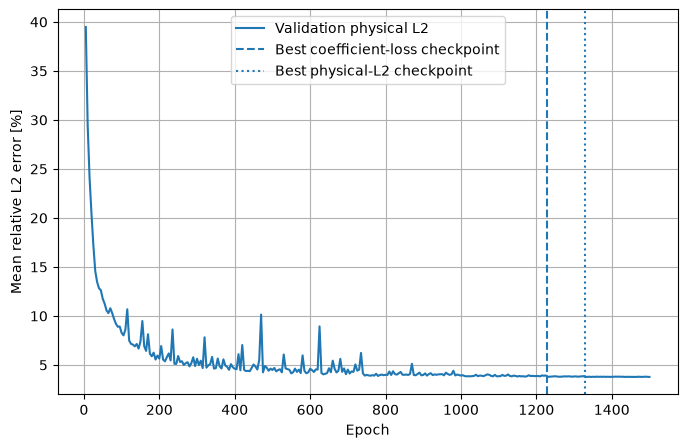

In [114]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    physical_epochs,
    100*np.array(physical_L2_history),
    label="Validation physical L2"
)

plt.axvline(
    best_coeff_epoch,
    linestyle="--",
    label="Best coefficient-loss checkpoint"
)

plt.axvline(
    best_physical_epoch,
    linestyle=":",
    label="Best physical-L2 checkpoint"
)

plt.xlabel("Epoch")
plt.ylabel("Mean relative L2 error [%]")
plt.legend()
plt.grid(True)
plt.show()

### Seed validation

In [116]:
import random

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [117]:
seed_results = {}
seed_models = {}

for seed in [0, 1, 2, 3, 4]:

    print("\n" + "=" * 70)
    print(f"SEED {seed}")
    print("=" * 70)

    set_seed(seed)

    model_i, train_history, val_history, best_val_loss, best_epoch = train_model(
        hidden_layers=[128, 128, 128, 128, 128],
        lr=1e-3,
        weight_decay=1e-4,
        activation="silu",
        max_epochs=1500
    )

    mean_err, worst_err, traj_err, snapshot_err = evaluate_model_L2(
        model_i,
        X_val_device,
        snapshots_val,
        V30,
        M,
        mu_val,
        N_t,
        a_range_tensor,
        a_min_tensor
    )

    seed_models[seed] = model_i

    seed_results[seed] = {
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "mean_L2_percent": 100 * mean_err,
        "worst_trajectory_mean_L2_percent": 100 * worst_err
    }

    print(f"Best epoch: {best_epoch}")
    print(f"Mean L2: {100*mean_err:.3f}%")
    print(
        f"Worst trajectory mean L2: "
        f"{100*worst_err:.3f}%"
    )


SEED 0
Epoch  250 | Train: 0.017796 | Val: 0.041332 | LR: 1.00e-03
Epoch  500 | Train: 0.010276 | Val: 0.015931 | LR: 1.00e-03
Epoch  750 | Train: 0.006067 | Val: 0.012561 | LR: 1.00e-03
Epoch 1000 | Train: 0.004104 | Val: 0.011660 | LR: 5.00e-04
Epoch 1250 | Train: 0.002660 | Val: 0.010242 | LR: 1.25e-04
Epoch 1500 | Train: 0.002427 | Val: 0.010562 | LR: 3.13e-05
Best epoch: 1243
Mean L2: 3.817%
Worst trajectory mean L2: 5.190%

SEED 1
Epoch  250 | Train: 0.024434 | Val: 0.032068 | LR: 1.00e-03
Epoch  500 | Train: 0.010608 | Val: 0.022676 | LR: 1.00e-03
Epoch  750 | Train: 0.005629 | Val: 0.013224 | LR: 1.00e-03
Epoch 1000 | Train: 0.005893 | Val: 0.017210 | LR: 5.00e-04
Epoch 1250 | Train: 0.003007 | Val: 0.011121 | LR: 2.50e-04
Epoch 1500 | Train: 0.002255 | Val: 0.010667 | LR: 3.13e-05
Best epoch: 1396
Mean L2: 3.797%
Worst trajectory mean L2: 4.911%

SEED 2
Epoch  250 | Train: 0.019832 | Val: 0.029044 | LR: 1.00e-03
Epoch  500 | Train: 0.009313 | Val: 0.016010 | LR: 1.00e-03
Epoc

In [118]:
seed_df = pd.DataFrame(seed_results).T
seed_df.index.name = "seed"

display(seed_df)

print("\nMean over seeds:")
print(
    f"{seed_df['mean_L2_percent'].mean():.3f}% "
    f"± {seed_df['mean_L2_percent'].std():.3f}%"
)

print("\nWorst-trajectory metric over seeds:")
print(
    f"{seed_df['worst_trajectory_mean_L2_percent'].mean():.3f}% "
    f"± {seed_df['worst_trajectory_mean_L2_percent'].std():.3f}%"
)

,best_epoch,best_val_loss,mean_L2_percent,worst_trajectory_mean_L2_percent
seed,,,,
0,1243.0,0.009460,3.816564,5.190483
1,1396.0,0.009785,3.796848,4.911080
2,1368.0,0.007821,3.804662,5.103464
3,1329.0,0.008768,3.752170,4.998975
4,1489.0,0.007487,3.720258,4.988466



Mean over seeds:
3.778% ± 0.040%

Worst-trajectory metric over seeds:
5.038% ± 0.109%


In [119]:
with pd.ExcelWriter(
    "architecture_results.xlsx",
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace"
) as writer:

    seed_df.to_excel(
        writer,
        sheet_name="Seeds"
    )

## TEST

In [142]:
# ============================================================
# TEST SET PREPARATION
# ============================================================

mu_test_repeated = np.repeat(mu_test, N_t, axis=0)
t_test = np.tile(t / T, len(mu_test)).reshape(-1, 1)

X_test_nn = np.hstack([
    mu_test_repeated,
    t_test
])

# Full-order test snapshots
snapshots_test = u_test.reshape(-1, u_test.shape[-1])

# POD coefficients of the test snapshots
# Useful for diagnostics, although NOT needed by the surrogate
A_test = snapshots_test @ V30

print("X test:", X_test_nn.shape)
print("A test:", A_test.shape)
print("Snapshots test:", snapshots_test.shape)

X test: (1025, 4)
A test: (1025, 30)
Snapshots test: (1025, 6636)


In [143]:
# ============================================================
# TEST SET PREPARATION
# ============================================================

# Build NN inputs: (mu1, mu2, mu3, t)
mu_test_repeated = np.repeat(mu_test, N_t, axis=0)
t_test = np.tile(t / T, len(mu_test)).reshape(-1, 1)

X_test_nn = np.hstack([
    mu_test_repeated,
    t_test
])

# Flatten FOM trajectories:
# (N_test, N_t, N_h) -> (N_test * N_t, N_h)
snapshots_test = u_test.reshape(-1, u_test.shape[-1])

# POD coefficients of test snapshots
# Not required for prediction, but useful for diagnostics
A_test = snapshots_test @ V30

# Convert to tensors
X_test_tensor = torch.tensor(
    X_test_nn,
    dtype=torch.float32
)

A_test_tensor = torch.tensor(
    A_test,
    dtype=torch.float32
)

X_test_device = X_test_tensor.to(device)

print("X test:        ", X_test_tensor.shape)
print("A test:        ", A_test_tensor.shape)
print("Snapshots test:", snapshots_test.shape)

X test:         torch.Size([1025, 4])
A test:         torch.Size([1025, 30])
Snapshots test: (1025, 6636)


In [144]:
model_test = seed_models[0]

In [145]:
# ============================================================
# FINAL TEST EVALUATION
# ============================================================

model_test.eval()

with torch.no_grad():

    # Predict scaled POD coefficients
    pred_test_scaled = model_test(X_test_device)

    # Return to original POD coefficient scale
    A_test_pred = (
        pred_test_scaled * a_range_tensor
        + a_min_tensor
    )

# Move coefficients to CPU / NumPy
A_test_pred = A_test_pred.cpu().numpy()

# Reconstruct full-order fields
snapshots_test_pred = A_test_pred @ V30.T

print("Predicted snapshots:", snapshots_test_pred.shape)

Predicted snapshots: (1025, 6636)


In [146]:
# ============================================================
# PHYSICAL RELATIVE L2 ERROR
# ============================================================

error_test = snapshots_test - snapshots_test_pred

# ||u - u_ROM||_L2^2
error_L2_sq = np.sum(
    (error_test @ M) * error_test,
    axis=1
)

# ||u||_L2^2
true_L2_sq = np.sum(
    (snapshots_test @ M) * snapshots_test,
    axis=1
)

# Relative L2 error for every snapshot
errors_test_L2_flat = np.sqrt(
    error_L2_sq / true_L2_sq
)

# Restore trajectory/time structure:
# (1025,) -> (25, 41)
errors_test_L2 = errors_test_L2_flat.reshape(
    len(mu_test),
    N_t
)

# Mean over time for each trajectory
trajectory_errors_test_L2 = errors_test_L2.mean(axis=1)

# Assignment metric:
# mean over trajectories of their time-averaged error
mean_test_L2 = trajectory_errors_test_L2.mean()

# Worst trajectory according to its mean-over-time error
worst_trajectory_mean_L2 = trajectory_errors_test_L2.max()

# Additional diagnostic: worst individual snapshot
max_instantaneous_L2 = errors_test_L2.max()

print(f"Mean test L2:                  {100*mean_test_L2:.3f}%")
print(f"Worst trajectory-mean L2:     {100*worst_trajectory_mean_L2:.3f}%")
print(f"Maximum instantaneous L2:     {100*max_instantaneous_L2:.3f}%")

Mean test L2:                  4.030%
Worst trajectory-mean L2:     9.497%
Maximum instantaneous L2:     39.218%


In [147]:
best_idx = np.argmin(trajectory_errors_test_L2)
worst_idx = np.argmax(trajectory_errors_test_L2)

# Trajectory closest to overall mean
representative_idx = np.argmin(
    np.abs(trajectory_errors_test_L2 - mean_test_L2)
)

print("\nBest trajectory:")
print(f"  index = {best_idx}")
print(f"  mu = {mu_test[best_idx]}")
print(f"  mean L2 = {100*trajectory_errors_test_L2[best_idx]:.3f}%")

print("\nRepresentative trajectory:")
print(f"  index = {representative_idx}")
print(f"  mu = {mu_test[representative_idx]}")
print(f"  mean L2 = {100*trajectory_errors_test_L2[representative_idx]:.3f}%")

print("\nWorst trajectory:")
print(f"  index = {worst_idx}")
print(f"  mu = {mu_test[worst_idx]}")
print(f"  mean L2 = {100*trajectory_errors_test_L2[worst_idx]:.3f}%")


Best trajectory:
  index = 14
  mu = [0.5507979  0.70814782 0.29090474]
  mean L2 = 2.243%

Representative trajectory:
  index = 6
  mu = [0.08734964 0.2304771  0.41106107]
  mean L2 = 4.014%

Worst trajectory:
  index = 19
  mu = [0.1530542  0.15768566 0.98549111]
  mean L2 = 9.497%


In [148]:
# Location of maximum instantaneous relative L2 error
worst_flat_idx = np.argmax(errors_test_L2)

worst_traj_idx, worst_time_idx = np.unravel_index(
    worst_flat_idx,
    errors_test_L2.shape
)

print("Maximum instantaneous error:")
print(f"  trajectory = {worst_traj_idx}")
print(f"  mu         = {mu_test[worst_traj_idx]}")
print(f"  time index = {worst_time_idx}")
print(f"  t          = {t[worst_time_idx]:.6f}")
print(f"  error      = {100*errors_test_L2[worst_traj_idx, worst_time_idx]:.3f}%")

# Error evolution of that trajectory
print("\nTrajectory mean:",
      f"{100*trajectory_errors_test_L2[worst_traj_idx]:.3f}%")

Maximum instantaneous error:
  trajectory = 19
  mu         = [0.1530542  0.15768566 0.98549111]
  time index = 0
  t          = 0.000000
  error      = 39.218%

Trajectory mean: 9.497%


### Speed of the process

In [149]:
import time
import numpy as np
import torch

model_test.eval()

# Representative test trajectory
idx = representative_idx

start = idx * N_t
end = (idx + 1) * N_t

X_traj = X_test_device[start:end]

# Warm-up
with torch.no_grad():
    for _ in range(20):
        pred_scaled = model_test(X_traj)
        pred_coeff = pred_scaled * a_range_tensor + a_min_tensor
        _ = pred_coeff.cpu().numpy() @ V30.T

# Timing
n_repeats = 500
times = []

with torch.no_grad():
    for _ in range(n_repeats):

        tic = time.perf_counter()

        # NN inference
        pred_scaled = model_test(X_traj)

        # Denormalization
        pred_coeff = pred_scaled * a_range_tensor + a_min_tensor

        # Full-order reconstruction
        snapshots_pred = pred_coeff.cpu().numpy() @ V30.T

        toc = time.perf_counter()

        times.append(toc - tic)

times = np.array(times)

rom_time_mean = times.mean()
rom_time_std = times.std()
rom_time_median = np.median(times)

fom_time = 19.33
speedup = fom_time / rom_time_mean

print(f"ROM trajectory time (mean):   {1e3*rom_time_mean:.3f} ms")
print(f"ROM trajectory time (median): {1e3*rom_time_median:.3f} ms")
print(f"Timing std:                   {1e3*rom_time_std:.3f} ms")
print(f"FOM trajectory time:          {fom_time:.3f} s")
print(f"Speed-up:                     {speedup:.0f}x")

ROM trajectory time (mean):   7.187 ms
ROM trajectory time (median): 5.820 ms
Timing std:                   4.581 ms
FOM trajectory time:          19.330 s
Speed-up:                     2689x


In [200]:
import numpy as np
import matplotlib.pyplot as plt
from dlroms.fespaces import gifs

def gif_compare(
    name,
    U,
    space,
    dt=None,
    T=None,
    titles=None,
    figsize=(15, 4),
    cmaps=None
):
    """
    Synchronized GIF for multiple FEM trajectories.

    Each element of U must have shape:
        (N_t, N_h)

    Each subplot has its own color scale.
    """

    u = U if isinstance(U, tuple) else (U,)

    n_plots = len(u)

    # Number of frames
    frames = len(u[0]) if T is None else (int(T // dt) + 1)

    N = len(u[0])
    step = N // frames

    # Independent color scales
    vmins = [float(uj.min()) for uj in u]
    vmaxs = [float(uj.max()) for uj in u]

    if titles is None:
        titles = [f"Field {j+1}" for j in range(n_plots)]

    if cmaps is None:
        cmaps = ["gray_jet"] * n_plots

    def drawframe(i):

        plt.figure(figsize=figsize)

        # Fixed common scale for FOM and POD-NN
        damage_min = min(
            float(u[0].min()),
            float(u[1].min())
        )

        damage_max = max(
            float(u[0].max()),
            float(u[1].max())
        )

        # -------------------------
        # FOM
        # -------------------------
        plt.subplot(1, 3, 1)

        fe.plot(
            u[0][i * step],
            space,
            vmin=damage_min,
            vmax=damage_max,
            cmap="gray_jet"
        )

        plt.title(
            f"FOM\n"
            f"t = {i * dt:.4f}"
        )

        # -------------------------
        # POD-NN
        # -------------------------
        plt.subplot(1, 3, 2)

        fe.plot(
            u[1][i * step],
            space,
            vmin=damage_min,
            vmax=damage_max,
            cmap="gray_jet"
        )

        plt.title(
            f"POD-NN\n"
            f"t = {i * dt:.4f}"
        )

        # -------------------------
        # ABSOLUTE ERROR
        # -------------------------
        plt.subplot(1, 3, 3)

        error_frame = u[2][i * step]

        # Dynamic scale for each frame
        error_max = float(error_frame.max())

        fe.plot(
            error_frame,
            space,
            vmin=0.0,
            vmax=max(error_max, 1e-12),
            cmap="magma"
        )

        plt.title(
            f"Absolute error\n"
            f"t = {i * dt:.4f}"
        )

        plt.tight_layout()

    gifs.save(drawframe, frames, name)

In [201]:
traj_idx = best_idx

# FOM
u_fom_traj = u_test[traj_idx]

if hasattr(u_fom_traj, "cpu"):
    u_fom_traj = u_fom_traj.cpu().numpy()

# POD-NN
start = traj_idx * N_t
end = (traj_idx + 1) * N_t

u_rom_traj = snapshots_test_pred[start:end]

# Absolute pointwise error
u_error_traj = np.abs(
    u_fom_traj - u_rom_traj
)

In [202]:
gif_compare(
    "PODNN_test_comparison.gif",

    (
        u_fom_traj,
        u_rom_traj,
        u_error_traj
    ),

    Vh,

    dt=0.0005,

    titles=[
        "FOM",
        "POD-NN",
        "Absolute error"
    ],

    cmaps=[
        "gray_jet",
        "gray_jet",
        "magma"
    ],

    figsize=(15, 4)
)

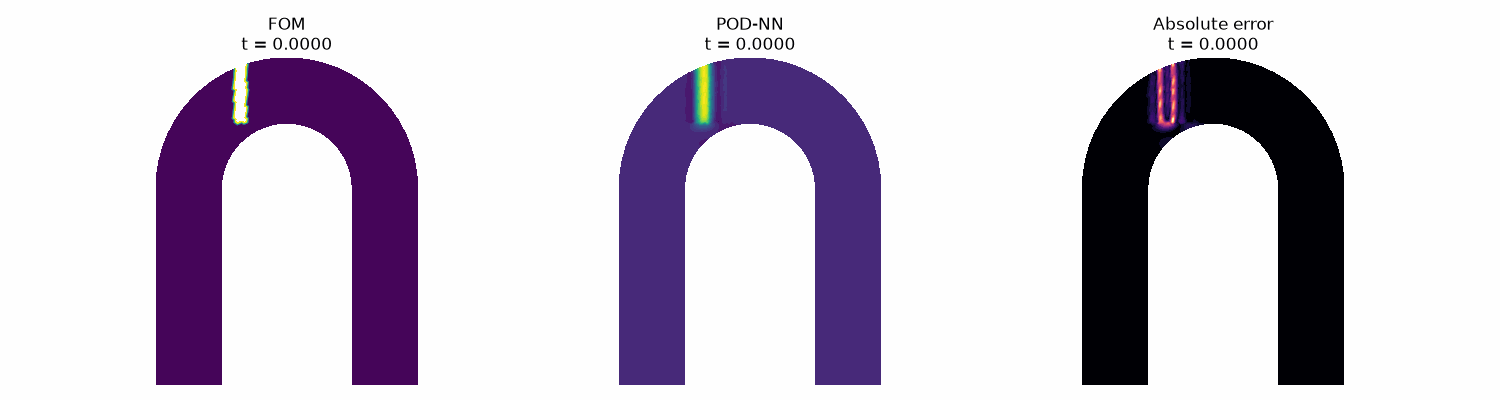

In [3]:
from IPython.display import Image, display

display(Image("PODNN_test_comparison.gif"))

In [ ]:
traj_idx = 19

u_true = u_test[traj_idx]

if hasattr(u_true, "cpu"):
    u_true = u_true.cpu().numpy()

# Exact POD projection
A_exact = u_true @ V30
u_pod = A_exact @ V30.T

# POD-NN prediction
start = traj_idx * N_t
end = (traj_idx + 1) * N_t

u_nn = snapshots_test_pred[start:end]


def relative_L2_over_time(u_true, u_pred, M):

    error = u_true - u_pred

    error_sq = np.sum(
        (error @ M) * error,
        axis=1
    )

    true_sq = np.sum(
        (u_true @ M) * u_true,
        axis=1
    )

    return np.sqrt(error_sq / true_sq)


pod_error_t = relative_L2_over_time(
    u_true,
    u_pod,
    M
)

podnn_error_t = relative_L2_over_time(
    u_true,
    u_nn,
    M
)

In [ ]:
plt.figure(figsize=(8, 4))

plt.plot(
    t,
    100 * pod_error_t,
    marker="o",
    label="POD projection"
)

plt.plot(
    t,
    100 * podnn_error_t,
    marker="o",
    label="POD-NN"
)

plt.xlabel("Time")
plt.ylabel("Relative $L^2$ error [%]")
plt.title(
    f"Error evolution – test trajectory {traj_idx}"
)

plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [4]:
true_norm_t = np.sqrt(
    np.sum((u_true @ M) * u_true, axis=1)
)

abs_error_norm_t = np.sqrt(
    np.sum(
        ((u_true - u_nn) @ M) * (u_true - u_nn),
        axis=1
    )
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    t,
    true_norm_t,
    marker="o",
    label=r"$||u||_{L^2}$"
)

ax.plot(
    t,
    abs_error_norm_t,
    marker="o",
    label=r"$||u-\tilde{u}||_{L^2}$"
)

ax.set_xlabel("Time")
ax.set_ylabel("$L^2$ norm")
ax.grid(alpha=0.3)
ax.legend()

plt.show()

NameError: name 'np' is not defined